In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("cs1090a_hw4.ipynb")

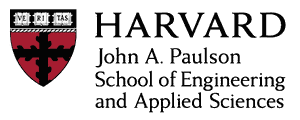

# CS1090A Introduction to Data Science
## Homework 4: Who gets in?
### Logistic regression, evaluating a classifier, Bayesian inference, and hierarchical models

**Harvard University**<br/>
**Fall 2026**<br/>
**Instructors**: Pavlos Protopapas, Kevin Rader, and Chris Gumb

<hr style="height:2.4pt">

## Instructions

CS1090A is graded out of 100 points. AC209A students complete the two marked extensions and are graded out of 110.

Run the import cell before beginning, then run each supplied cell when you reach it. Your submitted notebook must run in order after restarting the kernel, using the supplied local files; nothing in this assignment needs network access. A full run takes a few minutes, most of it the sampling cells in Parts 3 and 4. Include visible outputs, labeled plots, and written answers, and follow the Canvas submission instructions.

Use the split, the predictor list and the folds defined in the setup cell everywhere. Every number in Parts 1 and 2 comes from the training rows and the shared folds, except the last step of Q2.4, which uses the test rows once. Parts 3 and 4 use the training rows only.

Every `pm.sample` call uses `chains=2`, `draws=1000`, `tune=1000`, `random_seed=109` and `progressbar=False`. More chains or draws are fine; fewer are not. PyMC prints a message recommending at least four chains: two are enough for these models and keep the run short. PyMC's numbers can differ slightly between two computers even with the same seed, because floating-point arithmetic differs between machines; your answers should describe your own output.

Parts 1 and 2 and Q3.1 to Q3.2 use material taught before the release date. Q3.3, Q3.4, Part 4 and the AC209A extensions use the sampling and hierarchical-model material taught in the week of release.

**Use of AI tools**

You may use AI tools. You are accountable for everything you submit: you must understand it and be able to explain it.

- Written answers must be your own words.
- Quizzes and midterms ask you to explain and apply these methods without a tool.

All plots must have axis labels, a descriptive title, and a legend when colors, symbols, or reference lines distinguish information. Include units where applicable.

Written-response requests under **Constraints** are required parts of your answer, as are those listed under **Task** and **Artifacts**.

Each written response must contain at most three bullets. For questions with numbered written-response requests, use one bullet per request. Each bullet should contain a number from your output or a fact that a grader can check against it. Where a question lists **Output names for the guided checks**, these names identify variables checked by automated tests for their presence and specified properties, such as type, shape or range. These tests do not award points; the written responses and outputs are graded by the teaching staff.

In [2]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats
from scipy.optimize import minimize

from sklearn.base import clone
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, log_loss, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, GroupKFold, StratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import arviz as az
import pymc as pm

# Newer scikit-learn versions warn that the `penalty` argument is deprecated. This assignment still uses
# `penalty=None` and `penalty="l1"`; these two filters hide those warnings so they do not fill your output.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*penalty is deprecated.*")
# PyTensor warns once when it finds no BLAS library; sampling works without one.
warnings.filterwarnings("ignore", category=UserWarning, module="pytensor")

notebook_start = time.time()

# Setup. The data, the split, and the folds

This assignment predicts a yes or a no: whether an application to Harvard or Yale was admitted. The file `data/college_admissions.csv` has 1,871 applications scraped in 2022 from a website where applicants post their own results, and 27% of its rows are admissions.

The supplied cell below loads the file and makes a train/test split that is **stratified** on `admitted` (`stratify=df["admitted"]`): the training rows and the test rows each keep the same 27% share of admissions. With 468 test rows, an unstratified split could, by chance, give the test rows an admit rate a few percentage points above or below 27%. The accuracy of predicting "denied" for everyone equals the share of denied rows, so that baseline would change. The fitted classifiers' accuracies and their differences from the baseline could also change. The folds are `StratifiedKFold` for the same reason.

<details><summary><b>Column descriptions</b> (click to expand)</summary>

| Column | Description |
|---|---|
| `id` | applicant identifier; an applicant who applied to both colleges has two rows |
| `admitted` | 1 if the application was admitted, 0 if not (the outcome) |
| `test_score` | SAT or ACT score on the SAT scale, maximum 2,400 |
| `ap` | number of AP tests taken |
| `avg_ap` | average AP score (0 if none taken) |
| `sat_programs` | number of SAT subject tests taken |
| `gpa` | unweighted GPA, maximum 4.0 |
| `female` | 1 if the applicant reported female |
| `minority` | 1 if the applicant reported belonging to an underrepresented minority |
| `international` | 1 for an international applicant |
| `sports` | 1 for a high-school All-American athlete |
| `early_app` | 1 for an early application |
| `alumni` | 1 if a parent attended the college |
| `harvard` | 1 for an application to Harvard, 0 for Yale |
| `program` | the intended field of study, twenty levels (Part 4 only) |
| `add_info` | free text; not used |

</details>

In [3]:
# Supplied: the data, the split, the predictor list and the folds used everywhere below.
df = pd.read_csv("data/college_admissions.csv")

predictors = ["test_score", "ap", "avg_ap", "sat_programs", "gpa", "female", "minority",
              "international", "sports", "harvard", "early_app", "alumni"]

train_df, test_df = train_test_split(df, test_size=0.25, random_state=109, stratify=df["admitted"])
X_train, y_train = train_df[predictors], train_df["admitted"]
X_test, y_test = test_df[predictors], test_df["admitted"]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

print(f"{len(df):,} applications: {len(train_df):,} training rows and {len(test_df)} test rows")
print(f"share admitted in the training rows: {y_train.mean():.3f}")

1,871 applications: 1,403 training rows and 468 test rows
share admitted in the training rows: 0.270


# Part 1. A binary outcome

A straight line fitted to a 0/1 outcome can predict values below 0 and above 1. Logistic regression models the log-odds instead, $\log\frac{P(Y=1)}{1-P(Y=1)} = \beta_0 + \beta_1 X_1 + \dots + \beta_p X_p$, so that $P(Y=1) = 1/(1 + e^{-(\beta_0 + \beta_1 X_1 + \dots)})$ always lies between 0 and 1. A coefficient is a change in log-odds, and $e^{\beta_j}$ is the multiplicative change in the odds for a one-unit change in $X_j$.

## Q1.1. Compute the baseline and the admit rate by college

**5 points**

Before fitting a model, we need a **baseline**: the accuracy of a classifier that predicts the more common class for every applicant. Every accuracy in this assignment is compared with it. A logistic regression on a single 0/1 predictor has exactly two log-odds to match, one for each value of the predictor, so its two coefficients can be computed directly from a 2 × 2 table of counts, without fitting anything.

**Task:** Compute the training accuracy of the classifier that predicts the more common class for every applicant. Count the training rows in each combination of `harvard` and `admitted` with `pd.crosstab(train_df["harvard"], train_df["admitted"])`, and compute each college's admit rate from that table. Fit `LogisticRegression(penalty=None)` on `harvard` alone. Then compute its intercept and slope again from the four counts, without fitting: the intercept is the log-odds of admission at Yale, $\log(\text{admitted}/\text{denied})$, and the slope is Harvard's log-odds minus Yale's.

**Artifacts:** The baseline accuracy; the table and the two admit rates; the fitted and the by-hand coefficients side by side. In the written response: (1) the arithmetic for each by-hand coefficient, one line each; (2) the two admit rates in this file beside the published admit rates of these colleges, which are near 4%; (3) one consequence of that difference for reading any coefficient in this assignment as a statement about applicants in general.

**Constraints:** Training rows only. Use `penalty=None`: scikit-learn's default adds a penalty and changes the coefficients. The by-hand coefficients come from the counts, not from the fitted model.

**Output names for the guided checks:** `baseline_train_acc` (float), `admit_by_school` (the 2 × 2 crosstab), `logit_harvard`, `harvard_intercept_by_hand` and `harvard_slope_by_hand` (floats).

In [4]:
# Q1.1: the baseline, the admit rate at each college, and the harvard-only model fitted and by hand.
admit_share = y_train.mean()
baseline_train_acc = float(max(admit_share, 1 - admit_share))
print(f"baseline (predict 'denied' for everyone): training accuracy {baseline_train_acc:.3f}")

admit_by_school = pd.crosstab(train_df["harvard"], train_df["admitted"])
admit_rate_by_school = admit_by_school[1] / admit_by_school.sum(axis=1)
display(admit_by_school.rename(index={0: "0 (Yale)", 1: "1 (Harvard)"})
        .assign(admit_rate=admit_rate_by_school.to_numpy().round(3)))

# The default lbfgs solver stops once the gradient is below tol = 1e-4, a few ten-thousandths short of the
# maximum; newton-cholesky reaches the maximum, so the fitted coefficients match the counts exactly.
logit_harvard = LogisticRegression(penalty=None, solver="newton-cholesky").fit(train_df[["harvard"]], y_train)
harvard_intercept_by_hand = float(np.log(admit_by_school.loc[0, 1] / admit_by_school.loc[0, 0]))
harvard_slope_by_hand = float(np.log(admit_by_school.loc[1, 1] / admit_by_school.loc[1, 0])
                              - harvard_intercept_by_hand)
display(pd.DataFrame({"fitted": [logit_harvard.intercept_[0], logit_harvard.coef_[0, 0]],
                      "by hand from the counts": [harvard_intercept_by_hand, harvard_slope_by_hand]},
                     index=["intercept (Yale's log-odds)", "slope (Harvard's minus Yale's)"]).round(4))

baseline (predict 'denied' for everyone): training accuracy 0.730


admitted,0,1,admit_rate
harvard,,,
0 (Yale),518,171,0.248
1 (Harvard),506,208,0.291


,fitted,by hand from the counts
intercept (Yale's log-odds),-1.1083,-1.1083
slope (Harvard's minus Yale's),0.2193,0.2193


In [5]:
grader.check("q1_1")

q1_1 results: All test cases passed!

**Written response: Q1.1**

- **By hand:** the intercept is Yale's log-odds, log(171/518) = −1.1083, and the slope is Harvard's log-odds minus Yale's, log(208/506) − log(171/518) = −0.8890 + 1.1083 = 0.2193. Both match the fitted model to four decimals.
- **Admit rates:** 171/689 = 0.248 at Yale and 208/714 = 0.291 at Harvard in this file, six to seven times the published rates of about 4%.
- **Consequence:** the file over-represents admissions, most likely because admitted applicants are keener to post their results, so the intercept and every predicted probability are far too high for applicants in general (−1.108 means 24.8% at Yale). If posting also depends on the predictors, the slopes are biased too, so every coefficient in this assignment describes applicants who post on this website, not all applicants.

## Q1.2. Fit a straight line and a logistic regression on test score

**6 points**

The test score is the strongest single predictor in the file. Fitting it with a straight line first shows why a line is the wrong model for a probability. Fitting it with logistic regression then gives a coefficient that shows how the probability of admission rises with the score, even though the model's predictions at the usual 0.5 threshold turn out to be the same as the baseline's.

**Task:** Fit `LinearRegression()` to `admitted` on `test_score` (training rows) and record the smallest and largest fitted values. Fit `LogisticRegression(penalty=None)` on `test_score` alone and record its intercept and slope. From those two numbers, using $p = 1/(1 + e^{-(\beta_0 + \beta_1 \cdot \text{score})})$ rather than `predict_proba`, compute P(admitted) at scores of 2,000, 2,200 and 2,400; the score at which the predicted probability is exactly 0.5 (solve $\beta_0 + \beta_1 \cdot \text{score} = 0$); and the odds ratio per 100 points, $e^{100\beta_1}$. Compute the model's out-of-fold accuracy: `cross_val_predict` on the shared folds, then `accuracy_score` against `y_train`, and print how many applicants are predicted admitted out of fold.

**Artifacts:** The two fitted-value extremes; the logistic coefficients, the three probabilities, the 50% score, the odds ratio and the out-of-fold accuracy, all printed. In the written response: (1) the range of the straight line's fitted values, and what is wrong with a fitted value below 0; (2) why the logistic model's out-of-fold accuracy equals the baseline, using the number of applicants predicted admitted out of fold, and the 50% score beside the maximum possible score of 2,400; (3) the odds ratio per 100 points as a sentence comparing two applicants.

**Constraints:** Training rows and `skf`. `penalty=None`. Compute the three probabilities from the two coefficients, not from `predict_proba`.

**Output names for the guided checks:** `linreg_range` (a tuple of two floats), `logit_score`, `score_intercept`, `score_slope`, `score_at_50`, `odds_ratio_100`, `score_oof_acc` (floats) and `p_at` (a dict with keys 2000, 2200, 2400).

In [6]:
# Q1.2: a straight line and a logistic regression on test score alone.
score_only = train_df[["test_score"]]
line_fit = LinearRegression().fit(score_only, y_train).predict(score_only)
linreg_range = (float(line_fit.min()), float(line_fit.max()))
print(f"straight line: fitted values from {linreg_range[0]:.3f} to {linreg_range[1]:.3f}; "
      f"{int((line_fit < 0).sum())} training applicants get a fitted value below 0")

logit_score = LogisticRegression(penalty=None, solver="newton-cholesky").fit(score_only, y_train)
score_intercept, score_slope = float(logit_score.intercept_[0]), float(logit_score.coef_[0, 0])
p_at = {s: float(1 / (1 + np.exp(-(score_intercept + score_slope * s)))) for s in (2000, 2200, 2400)}
score_at_50 = -score_intercept / score_slope
odds_ratio_100 = float(np.exp(100 * score_slope))
print(f"logistic: intercept {score_intercept:.4f}, slope {score_slope:.6f} per point")
print("P(admitted) at " + ", ".join(f"{s:,}: {p:.3f}" for s, p in p_at.items()))
print(f"score where P(admitted) = 0.5: {score_at_50:,.0f} (maximum possible 2,400)")
print(f"odds ratio per 100 points: {odds_ratio_100:.3f}")

score_oof = cross_val_predict(LogisticRegression(penalty=None, solver="newton-cholesky"), score_only, y_train, cv=skf)
score_oof_acc = float(accuracy_score(y_train, score_oof))
print(f"out-of-fold accuracy {score_oof_acc:.3f} (baseline {baseline_train_acc:.3f}); "
      f"applicants predicted admitted out of fold: {int(score_oof.sum())} of {len(y_train)}")

straight line: fitted values from -0.300 to 0.393; 24 training applicants get a fitted value below 0
logistic: intercept -9.6365, slope 0.003909 per point
P(admitted) at 2,000: 0.140, 2,200: 0.262, 2,400: 0.437
score where P(admitted) = 0.5: 2,465 (maximum possible 2,400)
odds ratio per 100 points: 1.478
out-of-fold accuracy 0.730 (baseline 0.730); applicants predicted admitted out of fold: 0 of 1403


In [7]:
grader.check("q1_2")

q1_2 results: All test cases passed!

**Written response: Q1.2**

- **Straight line:** its fitted values run from −0.300 to 0.393, and 24 training applicants get a value below 0. A probability cannot be negative, so for low scorers the line predicts something impossible; it also makes the probability rise by the same amount for every extra point.
- **Accuracy equal to the baseline (0.730):** out of fold the logistic model predicts "admitted" for 0 of the 1,403 applicants. Its probability reaches 0.5 only at a score of 2,465, above the maximum possible 2,400 (where it is 0.437), so every applicant is called "denied", exactly as the baseline does.
- **Odds ratio 1.478 per 100 points:** of two applicants whose scores differ by 100 points, the higher scorer has 1.48 times the odds of admission (48% higher odds), whatever the two scores are; the probabilities themselves go from 0.140 at 2,000 to 0.262 at 2,200 and 0.437 at 2,400.

## Q1.3. Fit all twelve predictors, unscaled and standardized

**6 points**

With twelve predictors the coefficients are in different units: points of test score, numbers of AP tests, and binary predictors (often referred to as "flags"). Standardizing each column (subtracting its mean and dividing by its standard deviation) puts every coefficient in the same unit, log-odds per standard deviation of its column. The standardized model fitted here is the **working model**: Part 2 evaluates it on the training folds, and the test rows are used once, at the end of Q2.4, to evaluate it a final time.

For a 0/1 flag, one standard deviation is not a change an applicant can make; the flag is either 0 or 1. To read a flag's standardized coefficient $b$, divide it by the flag's standard deviation $s$: $b/s$ is the difference in log-odds between an applicant with the flag and one without, the other columns being equal.

**Task:** Fit `LogisticRegression(penalty=None, max_iter=10_000)` on all twelve predictors as they are. Fit the same model inside `make_pipeline(StandardScaler(), ...)`; this is the working model. For each, compute the training accuracy and the out-of-fold accuracy (`cross_val_predict` on `skf`). Put the working model's twelve coefficients in a `Series` indexed by `predictors` and sort it by absolute value, largest first. Then run the supplied cell below, which repeats the cross-validation with folds that put both rows of an applicant who applied to both colleges in the same fold, so that no applicant has one row in the training folds and the other in the validation fold.

**Artifacts:** A table of training and out-of-fold accuracy for the two models; the sorted standardized coefficients. In the written response: (1) why the two models have the same accuracies and different coefficients; (2) the two largest standardized coefficients, each as a sentence comparing two applicants; for a 0/1 flag, convert it to the with-versus-without difference using the flag's training standard deviation; (3) what the grouped-fold comparison shows, and what it does not settle about the test rows, given that some applicants have one row in the training set and the other in the test set.

**Constraints:** `penalty=None` in both. Sort with `coefs.reindex(coefs.abs().sort_values(ascending=False).index)`. Apply Q1.1's caution about the sample when reading `minority` or `alumni`.

**Output names for the guided checks:** `logit_full`, `working_model` (the fitted pipeline), `full_oof_acc` (the working model's out-of-fold accuracy, a float) and `coefs_per_sd` (a `Series` indexed by `predictors`).

In [8]:
# Q1.3: all twelve predictors, as they are and standardized (the working model).
# On the unscaled columns (test_score is in the thousands) lbfgs stops short of the maximum and its accuracy
# differs by a row or two; newton-cholesky reaches the same maximum as the standardized fit.
logit_full = LogisticRegression(penalty=None, solver="newton-cholesky", max_iter=10_000).fit(X_train, y_train)
working_model = make_pipeline(StandardScaler(),
                              LogisticRegression(penalty=None, max_iter=10_000)).fit(X_train, y_train)

accuracy_table = pd.DataFrame(
    {name: {"training accuracy": accuracy_score(y_train, model.predict(X_train)),
            "out-of-fold accuracy": accuracy_score(
                y_train, cross_val_predict(clone(model), X_train, y_train, cv=skf))}
     for name, model in [("unscaled", logit_full), ("standardized (working model)", working_model)]}).T
full_oof_acc = float(accuracy_table.loc["standardized (working model)", "out-of-fold accuracy"])
display(accuracy_table.round(4))

coefs = pd.Series(working_model[-1].coef_[0], index=predictors)
coefs_per_sd = coefs.reindex(coefs.abs().sort_values(ascending=False).index)
train_sd = pd.Series(working_model[0].scale_, index=predictors)[coefs_per_sd.index]  # the scaler's SDs
per_unit = coefs_per_sd / train_sd   # for a 0/1 flag: with minus without, in log-odds
display(pd.DataFrame({"per SD (working model)": coefs_per_sd,
                      "odds ratio per SD": np.exp(coefs_per_sd),
                      "training SD": train_sd,
                      "per unit = b / SD": per_unit,
                      "odds ratio per unit": np.exp(per_unit),
                      "unscaled fit": pd.Series(logit_full.coef_[0], index=predictors)[coefs_per_sd.index]}
                     ).round(4))

,training accuracy,out-of-fold accuracy
unscaled,0.7391,0.7341
standardized (working model),0.7391,0.7341


,per SD (working model),odds ratio per SD,training SD,per unit = b / SD,odds ratio per unit,unscaled fit
test_score,0.7863,2.1952,167.4742,0.0047,1.0047,0.0047
minority,0.4028,1.4960,0.4065,0.9910,2.6938,0.9915
sports,0.1724,1.1882,0.1836,0.9392,2.5578,0.9402
early_app,0.1636,1.1777,0.3891,0.4204,1.5226,0.4205
alumni,0.1526,1.1649,0.2132,0.7158,2.0459,0.7156
harvard,0.1411,1.1515,0.4999,0.2822,1.3261,0.2823
sat_programs,-0.1217,0.8854,1.2507,-0.0973,0.9073,-0.0974
gpa,0.1131,1.1198,0.1890,0.5986,1.8196,0.5996
ap,-0.0818,0.9214,2.2977,-0.0356,0.9650,-0.0361
international,0.0728,1.0755,0.2399,0.3036,1.3547,0.3051


In [9]:
grader.check("q1_3")

q1_3 results: All test cases passed!

In [10]:
# Supplied: the working model scored with stratified folds and with folds grouped on applicant id.
group_folds = GroupKFold(n_splits=5)
for label, cv, extra in (("StratifiedKFold (rows of one applicant can be split)", skf, {}),
                         ("GroupKFold on id (an applicant's rows stay together)", group_folds, {"groups": train_df["id"]})):
    acc = cross_val_score(working_model, X_train, y_train, cv=cv, **extra).mean()
    auc = cross_val_score(working_model, X_train, y_train, cv=cv, scoring="roc_auc", **extra).mean()
    print(f"{label:55s} accuracy {acc:.3f}   AUC {auc:.3f}")
print(f"\n{train_df['id'].isin(test_df['id']).sum()} training rows belong to an applicant who also has a row in the test set")

StratifiedKFold (rows of one applicant can be split)    accuracy 0.734   AUC 0.679
GroupKFold on id (an applicant's rows stay together)    accuracy 0.731   AUC 0.684

198 training rows belong to an applicant who also has a row in the test set


**Written response: Q1.3**

- **Same accuracies, different coefficients:** both models have training accuracy 0.7391 and out-of-fold accuracy 0.7341. Standardizing only shifts and rescales each column, and an unpenalized fit absorbs that exactly (the intercept takes the shifts and each slope is multiplied by its column's SD), so every applicant gets the same probability. Only the units change: test score is 0.0047 log-odds per point unscaled and 0.786 per SD (167 points) in the working model.
- **Two largest:** test score, 0.786 per SD: of two applicants equal on the other eleven columns, the one scoring 167 points higher has e^0.786 = 2.20 times the odds of admission. Minority, 0.4028 per SD with SD 0.4065, so 0.4028/0.4065 = 0.991 log-odds: an applicant who reports an underrepresented minority has e^0.991 = 2.69 times the odds of an otherwise equal applicant who does not, among the self-selected posters in this file (Q1.1), not applicants in general.
- **Grouped folds:** keeping each applicant's rows in one fold barely moves the scores (accuracy 0.734 to 0.731, AUC 0.679 to 0.684), so splitting an applicant across training and validation folds did not inflate the cross-validation. It does not settle the test rows: 198 training rows belong to applicants who also have a test row, the train/test split was not grouped, and this comparison only suggests that their effect on the test score is small.

<!-- BEGIN QUESTION -->

## Q1.4. Compare k-nearest neighbors with the baseline

**3 points**

k-nearest neighbors predicts an applicant's outcome from the outcomes of the k most similar training applicants. The supplied cell scores it out of fold for five values of k, with the scaler inside the pipeline, and plots the result against the baseline and the working model.

**Task:** Run the supplied cell and read the plot.

**Artifacts:** In the written response: (1) the out-of-fold accuracy at k = 1 against the baseline, and what it says about predicting each applicant from the single nearest training applicant; (2) whether any k beats the baseline by more than one percentage point; (3) why the scaler has to be inside the pipeline for kNN in particular.

**Constraints:** Use the supplied output; there is no code to write.

1     0.617
5     0.676
15    0.721
25    0.723
49    0.733


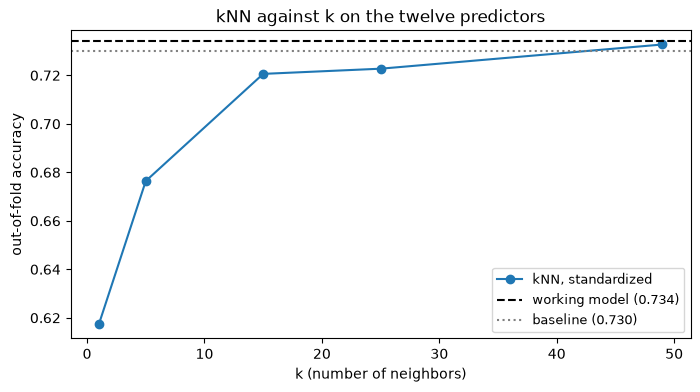

In [11]:
# Supplied: kNN at five values of k, scored out of fold on the shared folds.
ks = [1, 5, 15, 25, 49]
knn_oof_acc = pd.Series(
    [accuracy_score(y_train, cross_val_predict(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)),
                                               X_train, y_train, cv=skf)) for k in ks],
    index=ks, name="out-of-fold accuracy")
print(knn_oof_acc.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(knn_oof_acc.index, knn_oof_acc.values, marker="o", label="kNN, standardized")
ax.axhline(full_oof_acc, color="black", linestyle="--", label=f"working model ({full_oof_acc:.3f})")
ax.axhline(baseline_train_acc, color="grey", linestyle=":", label=f"baseline ({baseline_train_acc:.3f})")
ax.set(xlabel="k (number of neighbors)", ylabel="out-of-fold accuracy", title="kNN against k on the twelve predictors")
ax.legend(fontsize=9)
plt.show()

**Written response: Q1.4**

- **k = 1:** out-of-fold accuracy 0.617, 11 percentage points below the baseline's 0.730. Applicants who look alike on the twelve columns often had different outcomes, so copying the single nearest applicant's outcome mostly copies noise.
- **No k beats the baseline by more than one point:** the best is k = 49 at 0.733, 0.3 points above 0.730, while k = 15 and k = 25 (0.721 and 0.723) are below it.
- **Scaler:** kNN picks neighbors by Euclidean distance, so unscaled test scores (SD 167 points) would swamp the 0/1 flags (SD at most 0.5) and choose the neighbors alone. Logistic regression's predictions do not depend on the scaling (Q1.3), but kNN's do, and inside the pipeline each fold's means and SDs come from its training rows only, not from the rows being predicted.

<!-- END QUESTION -->

# Part 2. Is the model any good?

The working model's accuracy is less than one percentage point above the baseline's. Accuracy at 0.5 depends only on the predicted class, so a change in an applicant's probability that does not move it across 0.5 does not change the accuracy; accuracy also counts a false positive and a false negative the same way. This part uses summaries computed from the predicted probabilities themselves: the confusion matrix at several thresholds, the ROC curve, and the binary cross-entropy. When the model predicts "admitted" for an applicant, we say it **flags** that applicant.

Every question uses **out-of-fold probabilities**: each training row's probability comes from the model fitted on the four folds that do not contain that row, so the probabilities behave like predictions for applications the model was not fitted on. The test rows stay unused until the end of Q2.4.

In [12]:
# Supplied: the working model's out-of-fold P(admitted) for every training applicant.
p_oof = cross_val_predict(working_model, X_train, y_train, cv=skf, method="predict_proba")[:, 1]
print(f"out-of-fold probabilities: smallest {p_oof.min():.3f}, largest {p_oof.max():.3f}, "
      f"share at or above 0.5: {(p_oof >= 0.5).mean():.3f}")

out-of-fold probabilities: smallest 0.004, largest 0.837, share at or above 0.5: 0.074


## Q2.1. Read the out-of-fold confusion matrix at 0.5

**6 points**

A confusion matrix counts the four kinds of outcome: true negatives (tn), false positives (fp), false negatives (fn) and true positives (tp). **Precision** is the share of applicants predicted admitted who were admitted, tp / (tp + fp). **Recall** is the share of admitted applicants the model predicted admitted, tp / (tp + fn).

**Task:** Compute the confusion matrix of `p_oof >= 0.5` against `y_train` (`confusion_matrix(y_train, ...)`; rows are the truth, columns the prediction), and from it the accuracy, the precision, the recall and the number of admitted applicants the model flags (tp).

**Artifacts:** The labeled confusion matrix; accuracy, precision, recall and tp, printed. In the written response: (1) the four cells, and how many of the admitted applicants the model flags; (2) the accuracy against the baseline, and which cell of the matrix accounts for most of the accuracy; (3) the precision against the training admit rate, and what the comparison says about the applicants the model flags.

**Constraints:** Threshold 0.5 on `p_oof`. Read the four cells in `confusion_matrix`'s order: tn, fp, fn, tp.

**Output names for the guided checks:** `confusion_05` (2 × 2 array), `precision_05`, `recall_05` (floats) and `admits_found` (int).

In [13]:
# Q2.1: the out-of-fold confusion matrix at threshold 0.5.
pred_05 = (p_oof >= 0.5).astype(int)
confusion_05 = confusion_matrix(y_train, pred_05)
tn, fp, fn, tp = confusion_05.ravel()
precision_05 = float(precision_score(y_train, pred_05))
recall_05 = float(recall_score(y_train, pred_05))
admits_found = int(tp)
display(pd.DataFrame(confusion_05, index=["truth: denied", "truth: admitted"],
                     columns=["predicted denied", "predicted admitted"]))
print(f"accuracy {accuracy_score(y_train, pred_05):.3f} (baseline {baseline_train_acc:.3f}); "
      f"precision {precision_05:.3f}; recall {recall_05:.3f}")
print(f"admitted applicants flagged (tp): {admits_found} of {tp + fn}; "
      f"true negatives are {tn / (tn + tp):.1%} of the correct predictions")

,predicted denied,predicted admitted
truth: denied,975,49
truth: admitted,324,55


accuracy 0.734 (baseline 0.730); precision 0.529; recall 0.145
admitted applicants flagged (tp): 55 of 379; true negatives are 94.7% of the correct predictions


In [14]:
grader.check("q2_1")

q2_1 results: All test cases passed!

**Written response: Q2.1**

- **Cells:** tn = 975, fp = 49, fn = 324, tp = 55. The model flags 55 of the 379 admitted applicants (recall 0.145).
- **Accuracy 0.734 against the baseline's 0.730:** the true negatives are 975 of the 1,030 correct predictions (94.7%), so the accuracy comes almost entirely from calling denied applicants denied, which the baseline does for everyone.
- **Precision 0.529 against the admit rate of 0.270:** 55 of the 104 flagged applicants were admitted, about twice the training rate, so the flagged group is much more likely to be admitted than average, but it is small and misses 324 of the 379 admits.

## Q2.2. Choose a threshold for a fixed amount of review time

**6 points**

The threshold 0.5 is scikit-learn's default, not a requirement: any value between 0 and 1 gives a classifier, and the right one depends on how the predictions are used. A college counselor wants to review by hand the files of the applicants the model flags, and has time to review between 30% and 40% of all applicants. Choose the threshold using the out-of-fold probabilities, and fix it before the test rows are used; it does not change afterward.

**Task:** For each threshold in `[0.2, 0.3, 0.4, 0.5, 0.6]`, classify an applicant as admitted when `p_oof` is at or above it, and record the accuracy, precision, recall, the number predicted admitted and the share flagged. Choose the threshold whose share flagged is between 30% and 40% and store it as `chosen_threshold`.

**Artifacts:** The threshold table. In the written response: (1) the threshold you chose and the share of applicants it flags; (2) its recall and precision beside the values at 0.5; (3) how much lower the accuracy at your threshold is than the baseline's.

**Constraints:** Out-of-fold probabilities only; the test rows are not used. Once chosen, `chosen_threshold` does not change in the rest of the assignment.

**Output names for the guided checks:** `threshold_table` (a `DataFrame` indexed by the five thresholds with columns `accuracy`, `precision`, `recall`, `predicted_admits`, `share_flagged`) and `chosen_threshold` (float).

In [15]:
# Q2.2: five thresholds on the out-of-fold probabilities, and the one that fits the review time.
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]
rows = {}
for t in thresholds:
    flagged = (p_oof >= t).astype(int)
    rows[t] = {"accuracy": accuracy_score(y_train, flagged),
               "precision": precision_score(y_train, flagged, zero_division=0),
               "recall": recall_score(y_train, flagged),
               "predicted_admits": int(flagged.sum()),
               "share_flagged": flagged.mean()}
threshold_table = pd.DataFrame.from_dict(rows, orient="index")
threshold_table.index.name = "threshold"
display(threshold_table.round(3))

in_window = threshold_table.index[threshold_table["share_flagged"].between(0.30, 0.40)]
chosen_threshold = float(in_window[0])
print(f"thresholds flagging 30% to 40% of applicants: {list(in_window)}; chosen_threshold = {chosen_threshold}, "
      f"which flags {threshold_table.loc[chosen_threshold, 'share_flagged']:.1%}")

,accuracy,precision,recall,predicted_admits,share_flagged
threshold,,,,,
0.2,0.519,0.337,0.807,908,0.647
0.3,0.662,0.409,0.562,521,0.371
0.4,0.723,0.480,0.285,225,0.160
0.5,0.734,0.529,0.145,104,0.074
0.6,0.736,0.595,0.066,42,0.030


thresholds flagging 30% to 40% of applicants: [0.3]; chosen_threshold = 0.3, which flags 37.1%


In [16]:
grader.check("q2_2")

q2_2 results: All test cases passed!

**Written response: Q2.2**

- **Threshold 0.3:** it flags 521 applicants, 37.1%, the only one of the five thresholds inside the counselor's 30% to 40% (0.2 flags 64.7% and 0.4 flags 16.0%).
- **Recall 0.562 against 0.145 at 0.5, precision 0.409 against 0.529:** the counselor now sees 213 of the 379 admitted applicants instead of 55, at the cost of a lower share of admits among the flagged files.
- **Accuracy 0.662 against the baseline's 0.730:** 6.8 percentage points lower, because 308 denied applicants are now flagged; for a review list, finding admits matters more than accuracy.

## Q2.3. Draw the ROC curve and compute the binary cross-entropy

**8 points**

The two summaries in this question use every predicted probability, not only whether each probability is above one threshold. The **ROC curve** has one point for every possible threshold: the true-positive rate (the recall) against the false-positive rate (the share of denied applicants flagged). The **AUC** is the area under it: 1 for a perfect ranking, 0.5 for a random one. To interpret the AUC, choose one admitted and one denied applicant at random. The AUC equals the probability that the admitted applicant receives the higher predicted probability, plus half the probability that their predicted probabilities are equal. The **binary cross-entropy** is the average of $-[y_i \log p_i + (1 - y_i)\log(1 - p_i)]$ over applicants, the negative log-likelihood that logistic regression minimizes when it fits; lower is better, and scikit-learn computes it with `log_loss`. You may also see the binary cross-entropy written as a sum over applicants, without dividing by n. The version used here divides by n, so that values from data sets of different sizes can be compared.

**Task:** Draw the ROC curve of `p_oof` (`roc_curve(y_train, p_oof)`) with the five thresholds of Q2.2 marked and the diagonal of a random ranking, and compute the AUC (`roc_auc_score`). Compute the binary cross-entropy of `p_oof`, and of a base-rate model that gives every applicant in a validation fold the admit rate of that fold's training rows.

**Artifacts:** The ROC plot; the AUC and the two cross-entropies, printed. In the written response: (1) your AUC as a statement about one randomly chosen admitted and one randomly chosen denied applicant; (2) the true- and false-positive rates at `chosen_threshold`, read from the plot; (3) the two cross-entropies, and why the cross-entropy can improve on the base-rate model by more than accuracy improves on the baseline.

**Constraints:** Out-of-fold probabilities on the training rows. The AUC here is computed from all the pooled out-of-fold probabilities at once, which is close to but not the same as the average of five fold AUCs; call it the pooled out-of-fold AUC. Fit the base-rate model inside each fold: loop over `skf.split(X_train, y_train)`.

**Output names for the guided checks:** `oof_auc`, `bce_model` and `bce_base` (floats).

pooled out-of-fold AUC 0.679
binary cross-entropy: working model 0.5444, base-rate model 0.5834 (6.7% lower)
accuracy at 0.5: working model 0.734, baseline 0.730 (0.6% higher)
at chosen_threshold 0.3: true-positive rate 0.562, false-positive rate 0.301


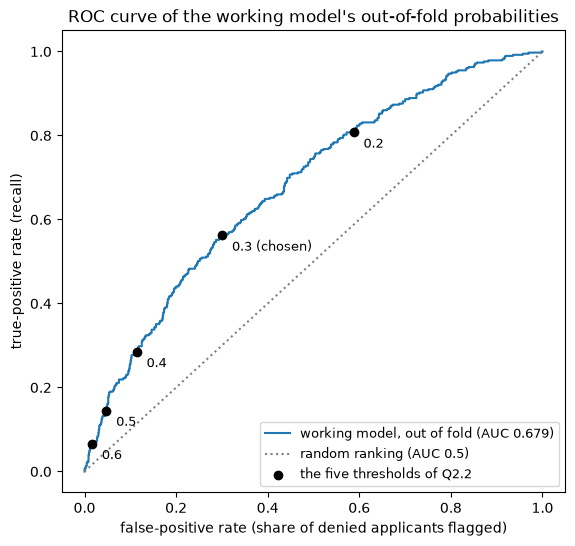

In [17]:
# Q2.3: the ROC curve, the pooled out-of-fold AUC and two binary cross-entropies.
fpr, tpr, _ = roc_curve(y_train, p_oof)
oof_auc = float(roc_auc_score(y_train, p_oof))
bce_model = float(log_loss(y_train, p_oof))

p_base = np.empty(len(y_train))   # each validation fold gets the admit rate of its training folds
for fit_rows, val_rows in skf.split(X_train, y_train):
    p_base[val_rows] = y_train.iloc[fit_rows].mean()
bce_base = float(log_loss(y_train, p_base))
print(f"pooled out-of-fold AUC {oof_auc:.3f}")
print(f"binary cross-entropy: working model {bce_model:.4f}, base-rate model {bce_base:.4f} "
      f"({1 - bce_model / bce_base:.1%} lower)")
print(f"accuracy at 0.5: working model {full_oof_acc:.3f}, baseline {baseline_train_acc:.3f} "
      f"({full_oof_acc / baseline_train_acc - 1:.1%} higher)")

truth = y_train.to_numpy()
marks = pd.DataFrame({"tpr": [np.mean(p_oof[truth == 1] >= t) for t in thresholds],
                      "fpr": [np.mean(p_oof[truth == 0] >= t) for t in thresholds]}, index=thresholds)
print(f"at chosen_threshold {chosen_threshold}: true-positive rate {marks.loc[chosen_threshold, 'tpr']:.3f}, "
      f"false-positive rate {marks.loc[chosen_threshold, 'fpr']:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(fpr, tpr, label=f"working model, out of fold (AUC {oof_auc:.3f})")
ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="random ranking (AUC 0.5)")
ax.scatter(marks["fpr"], marks["tpr"], color="black", zorder=3, label="the five thresholds of Q2.2")
for t, mark in marks.iterrows():
    ax.annotate(f"{t:g}" + (" (chosen)" if t == chosen_threshold else ""), (mark["fpr"], mark["tpr"]),
                textcoords="offset points", xytext=(7, -11), fontsize=9)
ax.set(xlabel="false-positive rate (share of denied applicants flagged)",
       ylabel="true-positive rate (recall)",
       title="ROC curve of the working model's out-of-fold probabilities")
ax.legend(loc="lower right", fontsize=9)
plt.show()

In [18]:
grader.check("q2_3")

q2_3 results: All test cases passed!

**Written response: Q2.3**

- **AUC 0.679:** if we draw one admitted and one denied applicant at random, the model gives the admitted one the higher out-of-fold probability 67.9% of the time (ties counted half), against 50% for a random ranking.
- **At `chosen_threshold` = 0.3:** the true-positive rate is 0.562 and the false-positive rate is 0.301, so 56% of the admitted applicants and 30% of the denied applicants are flagged.
- **Cross-entropy 0.5444 for the model against 0.5834 for the base-rate model (6.7% lower), while accuracy is only 0.6% above the baseline (0.734 against 0.730):** accuracy changes only when a probability crosses 0.5, which 7.4% of applicants do, but the cross-entropy rewards every probability that moves toward the truth, such as an admitted applicant whose probability rises from 0.27 to 0.45.

## Q2.4. Fit an L1-penalized model, then use the test rows once

**8 points**

An L1 penalty shrinks coefficients and sets some exactly to zero, so the predictors left with nonzero coefficients are the ones the penalized model uses. A smaller `C` is a stronger penalty, since scikit-learn's `C` is the inverse of the penalty strength. Once the penalty is chosen and the threshold fixed, the test rows give one estimate of how the working model performs on application rows that played no part in fitting it or in any choice about it. Some of those rows belong to applicants who also have a row in the training set (Q1.3).

**Task:** Search `C` in `[0.01, 0.03, 0.1, 1]` with `GridSearchCV` over `make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", random_state=0, max_iter=20_000))`, using `cv=skf` and `scoring="neg_log_loss"` (the negative of the cross-entropy). For each `C`, refit the pipeline on all training rows, count the nonzero coefficients and record which predictors are kept; build a table of the count and the cross-validated cross-entropy. Then, **once**: predict the test rows with the working model, classify at `chosen_threshold`, and report the accuracy, the confusion matrix, the recall, the share flagged and the AUC.

**Artifacts:** The table indexed by `C`; the kept predictors at each `C`; the test results. In the written response: (1) the five predictors kept at `C = 0.03`, and what they have in common as a description of an applicant; (2) the `C` the search chose, how many predictors it keeps, and its cross-entropy beside the five-predictor model's; (3) the test recall and share flagged at `chosen_threshold` beside the out-of-fold values in Q2.2.

**Constraints:** Choose `C` on the folds only. The scaler must be inside the searched pipeline so it is fit on each fold's training rows; `LogisticRegressionCV` placed after a scaler fitted on all training rows would compute the scaler's means and standard deviations from rows that later serve as validation rows. Use the test rows only in this question's last step, and do not change `chosen_threshold` after seeing them.

**Output names for the guided checks:** `lasso_search` (the fitted `GridSearchCV`), `lasso_table` (a `DataFrame` indexed by `C` with columns `nonzero` and `cv_cross_entropy`), `kept_at_003` (a list of column names) and `test_results` (a `Series`).

In [19]:
# Q2.4: the L1 search on the folds and the predictors kept at each C.
C_grid = [0.01, 0.03, 0.1, 1]
l1_pipeline = make_pipeline(StandardScaler(),
                            LogisticRegression(penalty="l1", solver="liblinear", random_state=0, max_iter=20_000))
lasso_search = GridSearchCV(l1_pipeline, {"logisticregression__C": C_grid}, cv=skf,
                            scoring="neg_log_loss").fit(X_train, y_train)
cv_cross_entropy = pd.Series(-lasso_search.cv_results_["mean_test_score"],
                             index=[p["logisticregression__C"] for p in lasso_search.cv_results_["params"]])
kept = {}
for C in C_grid:
    refit = clone(l1_pipeline).set_params(logisticregression__C=C).fit(X_train, y_train)
    kept[C] = [name for name, b in zip(predictors, refit[-1].coef_[0]) if b != 0]
lasso_table = pd.DataFrame({"nonzero": [len(kept[C]) for C in C_grid],
                            "cv_cross_entropy": [cv_cross_entropy.loc[C] for C in C_grid]},
                           index=pd.Index(C_grid, name="C"))
kept_at_003 = kept[0.03]
display(lasso_table.round(4))
for C in C_grid:
    print(f"C = {C}: {', '.join(kept[C])}")
print(f"GridSearchCV chose C = {lasso_search.best_params_['logisticregression__C']}")

# The test rows, used once: the working model of Q1.3, classified at chosen_threshold.
p_test = working_model.predict_proba(X_test)[:, 1]
flag_test = (p_test >= chosen_threshold).astype(int)
display(pd.DataFrame(confusion_matrix(y_test, flag_test), index=["truth: denied", "truth: admitted"],
                     columns=["predicted denied", "predicted admitted"]))
test_results = pd.Series({"accuracy": accuracy_score(y_test, flag_test),
                          "baseline accuracy": max(y_test.mean(), 1 - y_test.mean()),
                          "precision": precision_score(y_test, flag_test),
                          "recall": recall_score(y_test, flag_test),
                          "share_flagged": flag_test.mean(),
                          "auc": roc_auc_score(y_test, p_test)},
                         name=f"test rows, threshold {chosen_threshold}")
display(test_results.round(3).to_frame())

,nonzero,cv_cross_entropy
C,,
0.01,1,0.5986
0.03,5,0.5539
0.10,10,0.5439
1.00,12,0.5443


C = 0.01: test_score
C = 0.03: test_score, minority, sports, early_app, alumni
C = 0.1: test_score, sat_programs, gpa, female, minority, international, sports, harvard, early_app, alumni
C = 1: test_score, ap, avg_ap, sat_programs, gpa, female, minority, international, sports, harvard, early_app, alumni
GridSearchCV chose C = 0.1


,predicted denied,predicted admitted
truth: denied,241,101
truth: admitted,53,73


,"test rows, threshold 0.3"
accuracy,0.671
baseline accuracy,0.731
precision,0.420
recall,0.579
share_flagged,0.372
auc,0.694


In [20]:
grader.check("q2_4")

q2_4 results: All test cases passed!

**Written response: Q2.4**

- **Kept at C = 0.03:** `test_score`, `minority`, `sports`, `early_app` and `alumni`. Besides the test score, they are the well-known "hooks" of selective admissions, the flags that set an applicant apart from other strong applicants: an underrepresented minority, an All-American athlete, an early applicant and a legacy. GPA and the AP and subject-test counts drop out.
- **The search chose C = 0.1:** it keeps 10 predictors (all but `ap` and `avg_ap`), with a cross-validated cross-entropy of 0.5439 against 0.5539 for the five-predictor model at C = 0.03; C = 1 with all twelve is essentially tied (0.5443).
- **Test rows at 0.3:** recall 0.579 and share flagged 0.372, against 0.562 and 0.371 out of fold, so the threshold carries over to rows that played no part in the fit; the test accuracy is 0.671 against a test baseline of 0.731, and the test AUC is 0.694.

# Part 3. From a likelihood to a posterior

The likelihood is the probability of the observed data as a function of the parameters. Its maximum is the estimate scikit-learn returns. Bayes' rule multiplies the likelihood by a **prior** distribution for the parameters and rescales the product to a **posterior** distribution: posterior ∝ likelihood × prior. This part does the maximization by hand, then computes a posterior for one program's admit rate exactly, then samples the posterior of a five-predictor logistic regression with PyMC.

## Q3.1. Maximize the log-likelihood by hand

**6 points**

Logistic regression's estimates are the coefficients that make the observed outcomes most probable. Writing the negative log-likelihood yourself and minimizing it with a general-purpose optimizer should return the same coefficients scikit-learn reports.

**Task:** Write `neg_log_likelihood(beta, X, y)`: with $\eta_i = X_i \cdot \beta$, each row contributes $y_i \eta_i - \log(1 + e^{\eta_i})$ to the log-likelihood, and the function returns minus their sum. Build `X` with two columns, ones and `test_score / 1000` (dividing by 1,000 puts the two columns on similar scales, which helps the optimizer converge), and `y` as the training outcome. Minimize with `minimize(neg_log_likelihood, np.zeros(2), args=(X, y), method="BFGS")`. The fitted coefficients are `result.x` and the minimum value of the function is `result.fun`. Record the minimum, and the negative log-likelihood of the intercept-only model, `neg_log_likelihood([log-odds of the training admit rate, 0], X, y)`.

**Artifacts:** The two coefficients beside Q1.2's (with Q1.2's slope converted to per thousand points); the two negative log-likelihoods. In the written response: (1) whether your coefficients match Q1.2's, and why they should; (2) the two negative log-likelihoods, and what their difference measures.

**Constraints:** Use `np.logaddexp(0, eta)` for $\log(1 + e^{\eta})$; it gives the same value without overflowing when $\eta$ is large. `X[:, 1]` is `test_score / 1000`.

**Output names for the guided checks:** `neg_log_likelihood` (a function), `mle_beta` (array of length 2), `nll_at_mle` and `nll_intercept_only` (floats).

In [21]:
# Q3.1: the logistic log-likelihood written out and maximized with BFGS.
def neg_log_likelihood(beta, X, y):
    """Minus the Bernoulli log-likelihood of a logistic model whose log-odds are X @ beta."""
    eta = X @ np.asarray(beta, dtype=float)
    return -np.sum(y * eta - np.logaddexp(0, eta))

X = np.column_stack([np.ones(len(train_df)), train_df["test_score"].to_numpy() / 1000])
y = y_train.to_numpy()
result = minimize(neg_log_likelihood, np.zeros(2), args=(X, y), method="BFGS")
mle_beta = result.x
nll_at_mle = float(result.fun)
nll_intercept_only = float(neg_log_likelihood([np.log(y.mean() / (1 - y.mean())), 0.0], X, y))
display(pd.DataFrame({"BFGS by hand": mle_beta, "Q1.2 (slope x 1,000)": [score_intercept, 1000 * score_slope]},
                     index=["intercept", "slope per 1,000 points"]).round(4))
lr_statistic = 2 * (nll_intercept_only - nll_at_mle)
print(f"BFGS converged: {result.success}")
print(f"negative log-likelihood: at the MLE {nll_at_mle:.2f}, intercept only {nll_intercept_only:.2f}, "
      f"difference {nll_intercept_only - nll_at_mle:.2f}")
print(f"per applicant: {nll_at_mle / len(y):.4f} against {nll_intercept_only / len(y):.4f}; "
      f"likelihood-ratio statistic {lr_statistic:.1f} on 1 df, p = {stats.chi2.sf(lr_statistic, 1):.1e}")

,BFGS by hand,"Q1.2 (slope x 1,000)"
intercept,-9.6365,-9.6365
"slope per 1,000 points",3.9090,3.9090


BFGS converged: True
negative log-likelihood: at the MLE 778.81, intercept only 818.50, difference 39.69
per applicant: 0.5551 against 0.5834; likelihood-ratio statistic 79.4 on 1 df, p = 5.1e-19


In [22]:
grader.check("q3_1")

q3_1 results: All test cases passed!

**Written response: Q3.1**

- **They match:** BFGS gives an intercept of −9.6365 and a slope of 3.9090 per 1,000 points; Q1.2 gives −9.6365 and 0.003909 per point, which is 3.9090 per 1,000. They should match because `LogisticRegression(penalty=None)` maximizes this same log-likelihood, and dividing the score by 1,000 only multiplies the slope by 1,000.
- **Negative log-likelihoods:** 778.81 at the MLE and 818.50 for the intercept-only model. The difference, 39.69, measures how much better the test score explains the outcomes: they are e^39.69 times as probable under the fitted model, and twice the difference, 79.4, is the likelihood-ratio statistic (p = 5.1e-19 on 1 df). Per applicant the two are the training cross-entropies, 0.5551 and 0.5834.

## Q3.2. Compute the posterior for one small program

**7 points**

In the training rows, applicants to the Sociology/Anthropology program were admitted 7 times in 12. A rate estimated from twelve applicants is uncertain, and a prior is how other information, here the other programs' admit rate, is brought into the estimate. The **Beta distribution** Beta(a, b) is a distribution on [0, 1] with mean a/(a + b). With a Beta(a, b) prior and k admissions in n applicants, the posterior is Beta(a + k, b + n − k), and its mean (a + k)/(a + b + n) is a weighted average of the prior mean and k/n with weights a + b and n. The larger a + b is compared with n, the closer the posterior mean is to the prior mean. The supplied cell computes the admit rate of the other nineteen programs. The second prior below is centered on that rate, which is itself estimated from the same file; this question treats it as a known number.

**Task:** Record the program's admissions and applicants from `train_df`. Compute the posterior of its admit rate under a flat Beta(1, 1) prior, and under Beta($20\bar p$, $20(1 - \bar p)$), where $\bar p$ is `others_rate`: a prior centered on the other programs' rate with weight 20. For each, record the posterior mean and the 95% credible interval (`stats.beta(a, b).ppf([0.025, 0.975])`). Compute the Normal-approximation 95% confidence interval (often called the Wald interval) for the same rate, $\hat p \pm 1.96\sqrt{\hat p(1 - \hat p)/n}$ with $\hat p = k/n$. Plot the two posterior densities with the raw rate and `others_rate` marked.

**Artifacts:** The three intervals and two posterior means, printed; the plot. In the written response: (1) the two posterior means and credible intervals, and the Wald interval; (2) what "95%" refers to for a credible interval and for the Wald interval, one sentence each; (3) which estimate you would give the department as the program's admit rate, with one number from your output that supports the choice.

**Constraints:** Counts from the training rows. Use `scipy.stats.beta` for the posterior means and intervals.

**Output names for the guided checks:** `soc_k`, `soc_n` (ints), `soc_flat_mean`, `soc_prior20_mean` (floats), and `soc_flat_interval`, `soc_prior20_interval`, `soc_wald_interval` (tuples of two floats).

In [23]:
# Supplied: the admit rate of the other nineteen programs, the center of the second prior.
others = train_df["program"] != "Sociology/Anthropology"
others_rate = float(y_train[others].mean())
print(f"other nineteen programs: {int(y_train[others].sum())} admitted of {int(others.sum())}, rate {others_rate:.4f}")

other nineteen programs: 372 admitted of 1391, rate 0.2674


,estimate,2.5%,97.5%,width
"flat Beta(1, 1) prior: posterior mean, 95% credible interval",0.571,0.316,0.808,0.492
"Beta(5.35, 14.65) prior: posterior mean, 95% credible interval",0.386,0.228,0.557,0.330
raw rate 7/12: 95% Wald interval,0.583,0.304,0.862,0.558


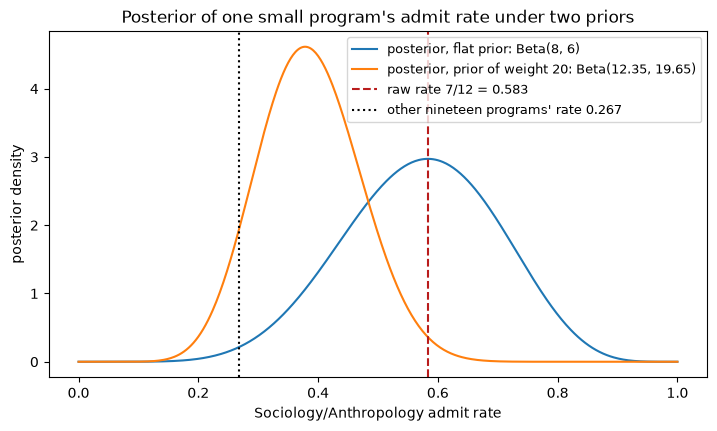

In [24]:
# Q3.2: Sociology/Anthropology's admit rate under two Beta priors, and the Wald interval.
soc = train_df["program"] == "Sociology/Anthropology"
soc_k, soc_n = int(y_train[soc].sum()), int(soc.sum())
prior_a, prior_b = 20 * others_rate, 20 * (1 - others_rate)
post_flat = stats.beta(1 + soc_k, 1 + soc_n - soc_k)
post_prior20 = stats.beta(prior_a + soc_k, prior_b + soc_n - soc_k)
soc_flat_mean, soc_prior20_mean = float(post_flat.mean()), float(post_prior20.mean())
soc_flat_interval = tuple(float(v) for v in post_flat.ppf([0.025, 0.975]))
soc_prior20_interval = tuple(float(v) for v in post_prior20.ppf([0.025, 0.975]))
p_hat = soc_k / soc_n
half_width = 1.96 * np.sqrt(p_hat * (1 - p_hat) / soc_n)
soc_wald_interval = (float(p_hat - half_width), float(p_hat + half_width))
display(pd.DataFrame({"estimate": [soc_flat_mean, soc_prior20_mean, p_hat],
                      "2.5%": [soc_flat_interval[0], soc_prior20_interval[0], soc_wald_interval[0]],
                      "97.5%": [soc_flat_interval[1], soc_prior20_interval[1], soc_wald_interval[1]],
                      "width": [np.diff(i)[0] for i in (soc_flat_interval, soc_prior20_interval, soc_wald_interval)]},
                     index=["flat Beta(1, 1) prior: posterior mean, 95% credible interval",
                            f"Beta({prior_a:.2f}, {prior_b:.2f}) prior: posterior mean, 95% credible interval",
                            f"raw rate {soc_k}/{soc_n}: 95% Wald interval"]).round(3))

grid = np.linspace(0, 1, 501)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(grid, post_flat.pdf(grid), label=f"posterior, flat prior: Beta({1 + soc_k}, {1 + soc_n - soc_k})")
ax.plot(grid, post_prior20.pdf(grid),
        label=f"posterior, prior of weight 20: Beta({prior_a + soc_k:.2f}, {prior_b + soc_n - soc_k:.2f})")
ax.axvline(p_hat, color="#B91C1C", linestyle="--", label=f"raw rate {soc_k}/{soc_n} = {p_hat:.3f}")
ax.axvline(others_rate, color="black", linestyle=":", label=f"other nineteen programs' rate {others_rate:.3f}")
ax.set(xlabel="Sociology/Anthropology admit rate", ylabel="posterior density",
       title="Posterior of one small program's admit rate under two priors")
ax.legend(fontsize=9)
plt.show()

In [25]:
grader.check("q3_2")

q3_2 results: All test cases passed!

**Written response: Q3.2**

- **Estimates:** with the flat Beta(1, 1) prior the posterior mean is 0.571 and the 95% credible interval [0.316, 0.808]; with the Beta(5.35, 14.65) prior they are 0.386 and [0.228, 0.557]; the Wald interval around 7/12 = 0.583 is [0.304, 0.862].
- **What "95%" means:** for a credible interval, given the data and the prior, the program's admit rate lies in the interval with probability 0.95. For the Wald interval, 95% describes the method: over repeated samples of 12 applicants, about 95% of the intervals built this way would contain the true rate (with n = 12 the Normal approximation is rough, so the real coverage can be lower).
- **For the department:** 0.386, the posterior mean under the prior centered on the other programs. Twelve applicants say little on their own (the Wald interval is 0.558 wide, against 0.330 for this posterior), and if the program is like the others, whose 1,391 applicants were admitted at 0.267, a rate near 0.58 is unlikely. The weight of 20 was our choice; Part 4 estimates it instead.

### The five-predictor design for Q3.3 and Q3.4

Q3.3 and Q3.4 fit the five predictors kept at `C = 0.03` in Q2.4 as a Bayesian logistic regression. The supplied cell builds the design by standardizing `test_score` on the training rows and leaving the four flags as 0 or 1. The test-score coefficient is therefore per standard deviation of the score, while each flag's coefficient is a with-versus-without difference. The same prior standard deviation is used for all five coefficients. It also fits the maximum-likelihood model on the same design and a 200-resample bootstrap of it (resampling rows), for Q3.3 to compare against.

In [26]:
# Supplied: the five-column design, the maximum-likelihood fit on it, and a bootstrap of that fit.
five = ["test_score", "minority", "early_app", "alumni", "sports"]
score_mean, score_sd = train_df["test_score"].mean(), train_df["test_score"].std()

X_five = train_df[five].to_numpy(dtype=float)
X_five[:, 0] = (X_five[:, 0] - score_mean) / score_sd          # test_score in standard deviations
y_five = y_train.to_numpy()

mle_model = LogisticRegression(penalty=None, max_iter=10_000).fit(X_five, y_five)
mle_five = pd.Series(np.r_[mle_model.intercept_, mle_model.coef_[0]], index=["intercept"] + five)

boot = []
for b in range(200):
    rows = np.random.default_rng(b).integers(0, len(y_five), len(y_five))
    refit = LogisticRegression(penalty=None, max_iter=10_000).fit(X_five[rows], y_five[rows])
    boot.append(np.r_[refit.intercept_, refit.coef_[0]])
bootstrap_sd_five = pd.Series(np.std(boot, axis=0), index=["intercept"] + five)

display(pd.DataFrame({"MLE": mle_five, "bootstrap sd": bootstrap_sd_five}).round(3))

,MLE,bootstrap sd
intercept,-1.462,0.095
test_score,0.770,0.089
minority,0.957,0.157
early_app,0.344,0.148
alumni,0.735,0.248
sports,0.836,0.335


## Q3.3. Sample the posterior of the five-predictor model in PyMC

**9 points**

A grid needs a point for every combination of parameter values, so its size grows exponentially with the number of parameters; with six parameters it is impractical, and PyMC draws samples from the posterior with a Markov chain Monte Carlo sampler instead. The draws are useful only if the chains have **converged**: each chain has moved away from its starting point and is drawing from the posterior, so different chains give the same distribution. `r_hat` compares the chains with one another (ArviZ's version splits each chain in half and works with ranks); a value above about 1.01 is a warning. `ess_bulk` estimates how many independent draws would estimate the posterior mean as precisely as these correlated draws do; `az.summary` also reports `ess_tail`, the same idea for the tails, which interval endpoints depend on. When consecutive draws are negatively correlated, the ESS can be larger than the number of draws. The `hdi_2.5%` and `hdi_97.5%` columns give a 95% **highest-density interval (HDI)**, the narrowest interval holding 95% of the draws; Q3.2's intervals were **equal-tailed**, from the 2.5th to the 97.5th percentile. The two are close when the posterior is symmetric.

**Task:** Write the model: `pm.Normal("intercept", 0, 2.5)`, `pm.Normal("beta", 0, 2.5, shape=5)`, the log-odds `intercept + pm.math.dot(X_five, beta)`, and `pm.Bernoulli("admitted", logit_p=..., observed=y_five)`. Sample with the shared settings. Summarize with `az.summary(idata, var_names=["intercept", "beta"], hdi_prob=0.95)`, set the index to `["intercept"] + five`, and keep the columns `mean`, `sd`, `hdi_2.5%`, `hdi_97.5%`, `ess_bulk`, `r_hat`. Draw the trace plot (`az.plot_trace(..., compact=False)`), so each coefficient has its own row; the `beta` rows numbered 0 to 4 are the five columns in the order of `five`. Put the posterior means and standard deviations beside `mle_five` and `bootstrap_sd_five` in one table.

**Artifacts:** The summary; the trace plot; the comparison table. In the written response: (1) how close the posterior means are to the MLE and the posterior standard deviations to the bootstrap's, naming the coefficient where they differ most; (2) the largest `r_hat` and the smallest `ess_bulk`, and the values that would make you distrust the run; (3) two limitations of these intervals: the five columns were chosen in Q2.4 using these same outcomes, and an applicant who applied to both colleges contributes two rows that the model treats as independent.

**Constraints:** `Normal(0, 2.5)` priors on every coefficient (`pm.Normal(name, 0, 2.5)` sets the standard deviation to 2.5, not the variance); the design `X_five` as supplied; the shared sampling settings.

**Output names for the guided checks:** `idata_five` (`InferenceData`) and `posterior_five` (a `DataFrame` indexed by `["intercept"] + five` with the six columns above).

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (2 chains in 2 jobs)


NUTS: [intercept, beta]


Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 1 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


,mean,sd,hdi_2.5%,hdi_97.5%,ess_bulk,r_hat
intercept,-1.465,0.090,-1.643,-1.296,1863.0,1.0
test_score,0.775,0.089,0.602,0.953,2169.0,1.0
minority,0.952,0.159,0.639,1.261,2072.0,1.0
early_app,0.345,0.151,0.052,0.635,1823.0,1.0
alumni,0.726,0.276,0.122,1.210,2034.0,1.0
sports,0.811,0.329,0.184,1.452,2161.0,1.0


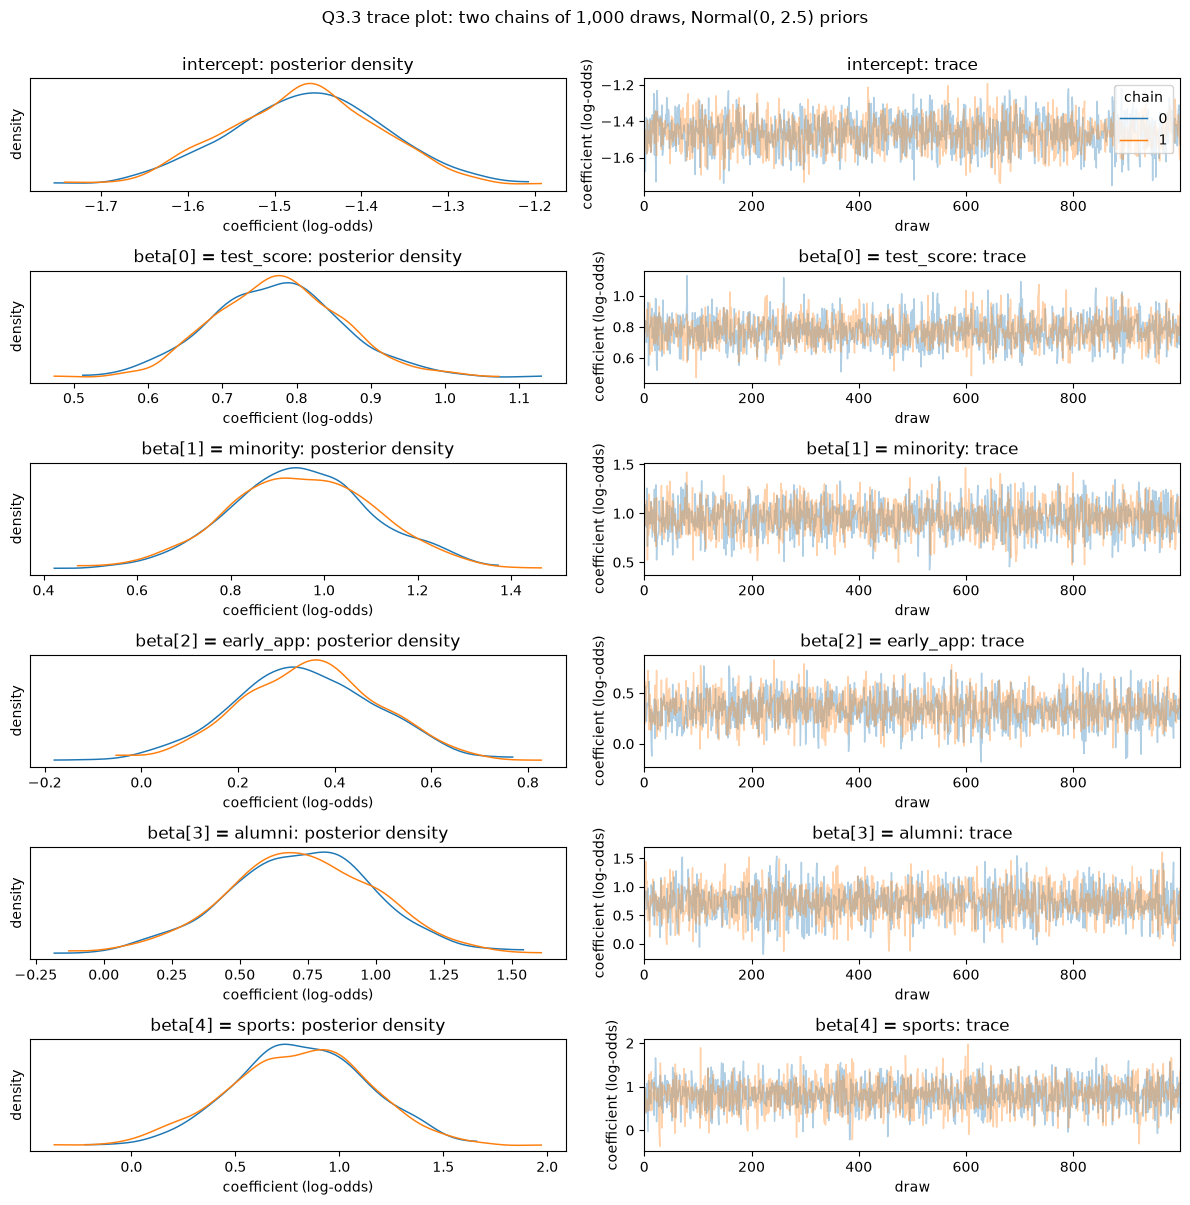

,MLE,posterior mean,bootstrap sd,posterior sd
intercept,-1.462,-1.465,0.095,0.090
test_score,0.770,0.775,0.089,0.089
minority,0.957,0.952,0.157,0.159
early_app,0.344,0.345,0.148,0.151
alumni,0.735,0.726,0.248,0.276
sports,0.836,0.811,0.335,0.329


279 applicants have both of their rows among the 1,403 training rows; the model treats each row as an independent applicant


In [27]:
# Q3.3: the five-predictor logistic regression sampled with PyMC.
SAMPLE = dict(draws=1000, tune=1000, chains=2, random_seed=109, progressbar=False)
SUMMARY_COLUMNS = ["mean", "sd", "hdi_2.5%", "hdi_97.5%", "ess_bulk", "r_hat"]


def sample_five(beta_sd):
    """Sample the five-predictor model with Normal(0, beta_sd) priors on the five coefficients."""
    with pm.Model():
        intercept = pm.Normal("intercept", 0, 2.5)
        beta = pm.Normal("beta", 0, beta_sd, shape=5)
        pm.Bernoulli("admitted", logit_p=intercept + pm.math.dot(X_five, beta), observed=y_five)
        return pm.sample(**SAMPLE)


def summarize_five(idata):
    """az.summary of the intercept and the five coefficients, indexed by predictor name."""
    summary = az.summary(idata, var_names=["intercept", "beta"], hdi_prob=0.95)
    return summary.set_axis(["intercept"] + five)[SUMMARY_COLUMNS]


idata_five = sample_five(2.5)
posterior_five = summarize_five(idata_five)
display(posterior_five)

axes = az.plot_trace(idata_five, var_names=["intercept", "beta"], compact=False, legend=True)
for row, name in zip(axes, ["intercept"] + [f"beta[{i}] = {c}" for i, c in enumerate(five)]):
    row[0].set(title=f"{name}: posterior density", xlabel="coefficient (log-odds)", ylabel="density")
    row[1].set(title=f"{name}: trace", xlabel="draw", ylabel="coefficient (log-odds)")
plt.gcf().suptitle("Q3.3 trace plot: two chains of 1,000 draws, Normal(0, 2.5) priors", y=1.0)
plt.tight_layout()
plt.show()

display(pd.DataFrame({"MLE": mle_five, "posterior mean": posterior_five["mean"],
                      "bootstrap sd": bootstrap_sd_five, "posterior sd": posterior_five["sd"]}).round(3))
rows_per_applicant = train_df["id"].value_counts()
print(f"{int((rows_per_applicant == 2).sum())} applicants have both of their rows among the "
      f"{len(train_df):,} training rows; the model treats each row as an independent applicant")

In [28]:
grader.check("q3_3")

q3_3 results: All test cases passed!

**Written response: Q3.3**

- **Closeness:** every posterior mean is within 0.025 of the MLE and every posterior SD within 0.03 of the bootstrap SD. The means differ most for `sports` (0.811 against 0.836) and the SDs for `alumni` (0.276 against 0.248), the two rarest flags, where the estimates rest on the fewest applicants.
- **Diagnostics:** the largest `r_hat` is 1.00 (all six) and the smallest `ess_bulk` is 1,823 (`early_app`) from 2,000 draws, and the two chains overlap in every row of the trace plot. We would distrust the run if any `r_hat` were above 1.01, if `ess_bulk` fell below a few hundred, or if the chains settled in different places.
- **Limitations:** the five columns were chosen in Q2.4 because they predicted these same outcomes, so the intervals ignore that selection and are likely too narrow and too far from zero. And 279 applicants have both of their rows in the training set, which the model treats as two independent applicants although the two outcomes are related, so it counts more information than there is and its intervals are again too narrow.

## Q3.4. Refit with two tighter priors

**6 points**

A Normal prior centered at zero gives coefficient values near zero a higher prior density than values far from zero, and a smaller standard deviation makes large coefficients even less plausible under the prior. This generally moves the estimates toward zero, although with correlated predictors an individual posterior mean need not move steadily toward zero as the prior narrows. Finding the most probable coefficients under independent Normal priors (the posterior mode) is the same as minimizing the negative log-likelihood plus a squared (ridge) penalty; independent Laplace priors give the absolute-value (L1) penalty of Q2.4 instead. Both priors are continuous distributions, so neither puts positive probability on any single value, including exactly zero.

**Task:** Refit Q3.3's model twice, changing only the prior on `beta`: `pm.Normal("beta", 0, 0.5, shape=5)`, then `pm.Normal("beta", 0, 0.1, shape=5)`. Keep the intercept's prior at 2.5 and the shared sampling settings. Build the same summary for each, and a table of the MLE and the three posterior means. List the coefficients whose 95% interval includes zero under the `Normal(0, 0.1)` prior.

**Artifacts:** The table of means; the intervals under the tightest prior. In the written response: (1) which coefficients moved most under each prior, with the numbers; (2) which 95% intervals include zero under `Normal(0, 0.1)`; (3) the direction of the correspondence with Q2.4's penalty: a smaller prior standard deviation favors coefficient values nearer zero, just as a smaller `C` gives a stronger penalty. Then explain why the squared penalty that a Normal prior corresponds to has no mechanism that sets a coefficient exactly to zero while the L1 penalty does, and why the posterior under a Normal prior, being a continuous distribution, gives the single value zero no probability.

**Constraints:** Only the prior width on `beta` changes between the three fits. Do not claim a numerical equivalence between a prior standard deviation and a value of `C`: the penalties differ in form (L1 against a Normal prior) and in how the intercept and the column scales are treated.

**Output names for the guided checks:** `posterior_tight` (prior sd 0.5) and `posterior_tighter` (prior sd 0.1), `DataFrame`s indexed like `posterior_five`.

In [29]:
# Q3.4: the same model with tighter priors on the five coefficients; the intercept keeps sd 2.5.
idata_tight = sample_five(0.5)
idata_tighter = sample_five(0.1)
posterior_tight = summarize_five(idata_tight)
posterior_tighter = summarize_five(idata_tighter)
print("prior sd 0.5:"); display(posterior_tight)
print("prior sd 0.1:"); display(posterior_tighter)

means = pd.DataFrame({"MLE": mle_five, "prior sd 2.5": posterior_five["mean"],
                      "prior sd 0.5": posterior_tight["mean"], "prior sd 0.1": posterior_tighter["mean"]})
means["change 2.5 to 0.5"] = means["prior sd 0.5"] - means["prior sd 2.5"]
means["change 2.5 to 0.1"] = means["prior sd 0.1"] - means["prior sd 2.5"]
display(means.round(3))

includes_zero = posterior_tighter.index[(posterior_tighter["hdi_2.5%"] <= 0) & (posterior_tighter["hdi_97.5%"] >= 0)]
print("95% intervals that include zero under Normal(0, 0.1):", list(includes_zero) or "none")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (2 chains in 2 jobs)


NUTS: [intercept, beta]


Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 1 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


Initializing NUTS using jitter+adapt_diag...


... (6 outputs left out)

prior sd 0.1:


,mean,sd,hdi_2.5%,hdi_97.5%,ess_bulk,r_hat
intercept,-1.115,0.068,-1.249,-0.986,2140.0,1.0
test_score,0.423,0.060,0.315,0.542,2006.0,1.0
minority,0.244,0.083,0.072,0.402,1614.0,1.0
early_app,0.119,0.083,-0.038,0.282,2214.0,1.0
alumni,0.094,0.097,-0.095,0.289,2599.0,1.0
sports,0.070,0.096,-0.112,0.265,2220.0,1.0


,MLE,prior sd 2.5,prior sd 0.5,prior sd 0.1,change 2.5 to 0.5,change 2.5 to 0.1
intercept,-1.462,-1.465,-1.412,-1.115,0.053,0.350
test_score,0.770,0.775,0.735,0.423,-0.040,-0.352
minority,0.957,0.952,0.862,0.244,-0.090,-0.708
early_app,0.344,0.345,0.324,0.119,-0.021,-0.226
alumni,0.735,0.726,0.564,0.094,-0.162,-0.632
sports,0.836,0.811,0.578,0.070,-0.233,-0.741


95% intervals that include zero under Normal(0, 0.1): ['early_app', 'alumni', 'sports']


In [30]:
grader.check("q3_4")

q3_4 results: All test cases passed!

**Written response: Q3.4**

- **Movement:** under Normal(0, 0.5), `sports` moved most (0.811 to 0.578, −0.233), then `alumni` (0.726 to 0.564, −0.162), the two rarest flags, whose likelihoods are flattest; `test_score` moved only −0.040. Under Normal(0, 0.1) every coefficient shrank by 0.23 to 0.74: `sports` by 0.741, `minority` by 0.708 and `alumni` by 0.632, while the intercept rose by 0.350 (−1.465 to −1.115) to keep the average predicted rate near the data's.
- **Intervals that include zero under Normal(0, 0.1):** `early_app` [−0.038, 0.282], `alumni` [−0.095, 0.289] and `sports` [−0.112, 0.265]; `test_score` [0.315, 0.542] and `minority` [0.072, 0.402] stay above zero.
- **Correspondence:** a smaller prior SD (2.5, 0.5, 0.1) pulls the coefficients toward zero, as a smaller C does (at C = 0.01 only `test_score` survives, and under Normal(0, 0.1) it is still the largest at 0.423). The squared penalty λβ² has slope 2λβ, which vanishes as β approaches zero, so near zero it barely resists the likelihood and the optimum is exactly zero only if the likelihood's own slope there is exactly zero; the L1 penalty λ|β| keeps slope λ all the way to zero, so whenever the likelihood's slope at zero is smaller than λ the optimum stops at exactly zero. A posterior under a Normal prior is a continuous density, so any single value, zero included, has probability zero: `sports` centers on 0.070 under Normal(0, 0.1), and its interval contains zero, yet zero itself gets no probability.

## AC209A Extension 1. Predict for two applicant profiles from the posterior draws (AC209A only)

**6 points**

Q3.3's posterior draws can answer questions about new applicants. Each draw of the intercept and the five coefficients gives one value of an applicant's admission probability, so the draws together give the posterior distribution of that probability. Because the draws are paired (each draw of the intercept goes with the coefficients from the same iteration), any quantity computed from several coefficients, such as a difference between two applicants, gets its posterior distribution the same way. The **posterior predictive distribution** adds one more step: for each draw, it simulates yes-or-no admission outcomes with that draw's probability.

**Task:** Use two profiles on Q3.3's design: applicant A has the training-average test score (0 on the standardized scale) and all four flags equal to 0; applicant B is the same except `alumni = 1`. From `idata_five`, take the paired draws of `intercept` and `beta` and compute, for every draw, the admission probability of each profile. Compute the difference B minus A for every draw, and report its posterior mean, its equal-tailed 95% credible interval (2.5th and 97.5th percentiles of the draws) and the posterior probability that it is above 0. Then, with `rng = np.random.default_rng(109)`, simulate for every draw the number admitted out of 10 applicants of each profile (`rng.binomial(10, p)`), and report the 95% interval of those counts beside 10 times the 95% interval of each profile's probability.

**Artifacts:** A table of each profile's posterior mean probability and its 95% interval; the difference's mean, interval and probability of being above 0; the count intervals beside 10 times the probability intervals. In the written response: (1) the difference's mean, interval and probability above 0; (2) why the interval for the number admitted out of 10 is wider than 10 times the probability interval; (3) one reason this difference is not the effect of having an alumni parent.

**Constraints:** Q3.3's posterior draws only; do not refit. Keep each draw's intercept and coefficients together. CS1090A students skip this extension.

**Output names for the guided checks:** `p_profiles` (array with one row per posterior draw and two columns, A then B), `prob_diff` (array, B minus A, one entry per draw) and `admit_counts` (integer array, same shape as `p_profiles`).

In [31]:
# AC209A Extension 1: two applicant profiles from Q3.3's paired posterior draws.
draws = idata_five.posterior.stack(sample=("chain", "draw"))
intercept_draws = draws["intercept"].to_numpy()                   # one value per draw
beta_draws = draws["beta"].transpose("sample", ...).to_numpy()    # one row per draw, in the same order
profile_A = np.zeros(5)                                           # average test score, all four flags 0
profile_B = profile_A.copy()
profile_B[five.index("alumni")] = 1                               # the same applicant with an alumni parent
p_profiles = 1 / (1 + np.exp(-(intercept_draws[:, None] + beta_draws @ np.column_stack([profile_A, profile_B]))))
prob_diff = p_profiles[:, 1] - p_profiles[:, 0]
rng = np.random.default_rng(109)
admit_counts = rng.binomial(10, p_profiles)

profile_table = pd.DataFrame(np.column_stack([p_profiles, prob_diff]), columns=["A", "B", "B minus A"]).agg(
    [np.mean, lambda d: np.percentile(d, 2.5), lambda d: np.percentile(d, 97.5)]).T
profile_table.columns = ["posterior mean", "2.5%", "97.5%"]
display(profile_table.round(3))
print(f"P(B minus A > 0) = {np.mean(prob_diff > 0):.3f} over {len(prob_diff):,} draws")

display(pd.DataFrame({"admitted of 10: 2.5%": np.quantile(admit_counts, 0.025, axis=0, method="inverted_cdf"),
                      "admitted of 10: 97.5%": np.quantile(admit_counts, 0.975, axis=0, method="inverted_cdf"),
                      "10 x probability: 2.5%": 10 * np.percentile(p_profiles, 2.5, axis=0),
                      "10 x probability: 97.5%": 10 * np.percentile(p_profiles, 97.5, axis=0)},
                     index=["A", "B"]).round(2))

,posterior mean,2.5%,97.5%
A,0.188,0.162,0.216
B,0.326,0.216,0.450
B minus A,0.138,0.027,0.260


P(B minus A > 0) = 0.995 over 2,000 draws


,admitted of 10: 2.5%,admitted of 10: 97.5%,10 x probability: 2.5%,10 x probability: 97.5%
A,0,5,1.62,2.16
B,0,7,2.16,4.50


In [32]:
grader.check("q3_ac209")

q3_ac209 results: All test cases passed!

**Written response: AC209A Extension 1**

- **B minus A:** posterior mean 0.138, 95% interval [0.027, 0.260], and P(B − A > 0) = 0.995; A's probability is 0.188 [0.162, 0.216] and B's is 0.326 [0.216, 0.450].
- **Counts out of 10:** A's interval is 0 to 5 admitted, against 1.62 to 2.16 for 10 times its probability interval, and B's is 0 to 7 against 2.16 to 4.50. The probability interval reflects only our uncertainty about p; the count adds the randomness of ten yes-or-no outcomes for a given p, which alone has an SD of √(10 × 0.19 × 0.81) ≈ 1.2 admissions for A, far more than the uncertainty in p.
- **Not an effect:** applicants with an alumni parent differ from other applicants in ways the five columns do not record, such as family income, school and essays, and B and A are compared without holding those fixed; within this self-selected sample the 0.138 is an association, not what would happen if the same applicant gained an alumni parent.

# Part 4. Twenty programs, some with twelve applicants

Q3.2 estimated one program's admit rate using a Beta prior whose weight, 20, was chosen by hand. A **hierarchical model** instead estimates, from the data, how much the programs differ. Each program $j$ has its own log-odds of admission $\alpha_j$, and the twenty $\alpha_j$ are modeled as draws from a common distribution, $\alpha_j \sim N(\alpha_0, \sigma_\alpha^2)$. Here $\alpha_0$ is the mean of that distribution, the log-odds of a typical program, and $\sigma_\alpha$ is its standard deviation. A small $\sigma_\alpha$ means the programs' log-odds are similar, so each program's estimate is drawn close to the typical program's; a large $\sigma_\alpha$ allows bigger differences, so a program's estimate can stay closer to its own raw rate. Treating all programs as having one admit rate is called **complete pooling**. Estimating each program's rate from its own rows alone is called **no pooling**. Using both a program's own outcomes and information shared across programs is called **partial pooling**. The resulting movement of the estimates toward the common center is called **shrinkage**.

## Q4.1. Tabulate the raw rates and predict which will move

**4 points**

Before fitting the model, write down what you expect it to do. Q4.3 asks you to check the prediction against the fitted model; the reasoning is graded, not whether the prediction turns out right.

**Task:** Build a `DataFrame` indexed by `program` with the number of training applicants (`n`), the number admitted (`admitted`) and the raw admit rate (`raw_rate`), sorted by `n`. Record the pooled training admit rate.

**Artifacts:** The table and the pooled rate. In the written response, written before Q4.2 is run: (1) the programs you expect a hierarchical model to leave near their raw rate and those you expect it to move, each named with its `n`; (2) the reason, using each program's `n` and how far its raw rate is from the pooled rate. How far each program moves also depends on how much the programs truly differ. Q4.2 estimates that, so you do not know it yet.

**Constraints:** Training rows only.

**Output names for the guided checks:** `program_table` (indexed by program, columns `n`, `admitted`, `raw_rate`, sorted by `n` ascending) and `pooled_rate` (float).

In [33]:
# Q4.1: each program's training applicants, admissions and raw admit rate, smallest program first.
program_table = (train_df.groupby("program")["admitted"].agg(n="size", admitted="sum")
                 .assign(raw_rate=lambda t: t["admitted"] / t["n"])
                 .sort_values("n", kind="stable"))
pooled_rate = float(y_train.mean())
# How far each raw rate is from the pooled rate, in binomial standard errors at the pooled rate.
standard_errors = np.sqrt(pooled_rate * (1 - pooled_rate) / program_table["n"])
display(program_table.assign(raw_minus_pooled=program_table["raw_rate"] - pooled_rate,
                             standard_errors_from_pooled=(program_table["raw_rate"] - pooled_rate) / standard_errors)
        .round(3))
print(f"pooled training admit rate {pooled_rate:.3f}")

,n,admitted,raw_rate,raw_minus_pooled,standard_errors_from_pooled
program,,,,,
Humanities (General),10,2,0.200,-0.070,-0.499
Philosophy,12,3,0.250,-0.020,-0.157
Sociology/Anthropology,12,7,0.583,0.313,2.443
Environmental & Earth,15,4,0.267,-0.003,-0.030
Law/Policy,15,7,0.467,0.197,1.714
History,33,9,0.273,0.003,0.034
Arts/Media/Architecture,34,5,0.147,-0.123,-1.616
Undecided/Undeclared,38,9,0.237,-0.033,-0.462
Chemistry,40,13,0.325,0.055,0.781


pooled training admit rate 0.270


In [34]:
grader.check("q4_1")

q4_1 results: All test cases passed!

**Written response: Q4.1**

- **Near their raw rates:** the five largest programs, Other/Unknown (n = 191, 0.298), Biology & Life Sciences (n = 157, 0.210), Economics & Business (n = 148, 0.297), Engineering (n = 147, 0.259) and Political Science & IR (n = 141, 0.277), and the programs already close to the pooled 0.270, such as Environmental & Earth (n = 15, 0.267) and History (n = 33, 0.273). **Moving:** Sociology/Anthropology (n = 12, 0.583) and Law/Policy (n = 15, 0.467) down toward 0.270 the most, then Pre-Med/Health (n = 58, 0.138) and Arts/Media/Architecture (n = 34, 0.147) up toward it.
- **Reason:** a rate from a dozen applicants is noisy, so the model should trust it less and pull it toward the pooled rate, while a program with 150 applicants has a precise rate and keeps it. The pull also grows with the distance from the pooled rate: Sociology/Anthropology is 0.313 above it with n = 12, 2.4 binomial standard errors and the largest gap in the table, while Environmental & Earth is 0.003 away, so even with n = 15 it has almost nothing to move.

In [35]:
# Supplied: each training applicant's program as an integer code 0..19, in program_table's order.
program_codes = pd.Categorical(train_df["program"], categories=program_table.index)
program_idx = program_codes.codes
n_programs = len(program_table)
print(f"{n_programs} programs; the first five applicants belong to programs {program_idx[:5].tolist()}")

20 programs; the first five applicants belong to programs [19, 18, 18, 15, 18]


## Q4.2. Fit the varying-intercept model

**7 points**

Sampling $\alpha_j \sim N(\alpha_0, \sigma_\alpha^2)$ directly is hard for the sampler when $\sigma_\alpha$ is small, because the twenty $\alpha_j$ and $\sigma_\alpha$ then depend strongly on one another. The **non-centered** form samples $z_j \sim N(0, 1)$ and computes $\alpha_j = \alpha_0 + \sigma_\alpha z_j$, which describes the same model and usually samples more reliably. To propose each new draw, PyMC's sampler simulates a path through the space of parameter values in many small numerical steps. A **divergence** is an iteration where that simulation's numerical error became very large, which happens where the posterior's shape changes sharply over a short distance; the sampler then does not visit that region, so the summaries can be biased. A run you use should have none. `target_accept=0.9` asks PyMC to tune a smaller step size than its default (0.8), which makes divergences less likely.

**Task:** Fit the model with `alpha0 = pm.Normal("alpha0", 0, 2.5)`, `sigma_alpha = pm.HalfNormal("sigma_alpha", 1.0)`, `z = pm.Normal("z", 0, 1, shape=n_programs)`, `logit_p = pm.Deterministic("logit_p", alpha0 + sigma_alpha * z)`, and `pm.Bernoulli("admitted", logit_p=logit_p[program_idx], observed=y_train.to_numpy())`. Sample with the shared settings plus `target_accept=0.9`. Summarize `alpha0` and `sigma_alpha` (`hdi_prob=0.95`); count the divergences (`idata.sample_stats["diverging"].sum()`); record the largest `r_hat` over the twenty `logit_p` with `float(az.rhat(idata, var_names=["logit_p"])["logit_p"].max())`; `az.summary` rounds `r_hat` to two decimals and `az.rhat` does not; and compute the posterior probability that `sigma_alpha` is below 0.1, the share of its draws below 0.1.

**Artifacts:** The summary and the two diagnostics, printed. In the written response: (1) the posterior mean and 95% interval of `sigma_alpha`, and which quantity it is the standard deviation of; (2) what `sigma_alpha` equal to zero would mean for the twenty programs, then the posterior probability that `sigma_alpha` is below 0.1 beside the prior's probability of the same event (0.08 under `HalfNormal(1)`), and what a between-program SD that small would mean for the programs' admit rates; (3) the divergences, the largest `r_hat` and the smallest `ess_bulk` in `hier_summary` (over `alpha0` and `sigma_alpha`), and whether you trust the run.

**Constraints:** Non-centered as specified; `target_accept=0.9`; the shared sampling settings. The likelihood is over applicants (`pm.Bernoulli`), indexed by `program_idx`.

**Output names for the guided checks:** `idata_programs` (`InferenceData`), `hier_summary` (from `az.summary(idata_programs, var_names=["alpha0", "sigma_alpha"], hdi_prob=0.95)`), `n_divergences` (int), `max_rhat_programs` (float) and `p_sigma_alpha_small` (float).

In [36]:
# Q4.2: varying intercepts by program, non-centered.
with pm.Model() as program_model:
    alpha0 = pm.Normal("alpha0", 0, 2.5)
    sigma_alpha = pm.HalfNormal("sigma_alpha", 1.0)
    z = pm.Normal("z", 0, 1, shape=n_programs)
    logit_p = pm.Deterministic("logit_p", alpha0 + sigma_alpha * z)
    pm.Bernoulli("admitted", logit_p=logit_p[program_idx], observed=y_train.to_numpy())
    idata_programs = pm.sample(**SAMPLE, target_accept=0.9)

hier_summary = az.summary(idata_programs, var_names=["alpha0", "sigma_alpha"], hdi_prob=0.95)
n_divergences = int(idata_programs.sample_stats["diverging"].sum())
max_rhat_programs = float(az.rhat(idata_programs, var_names=["logit_p"])["logit_p"].max())
p_sigma_alpha_small = float((idata_programs.posterior["sigma_alpha"] < 0.1).mean())
display(hier_summary)
rhat_programs = pd.Series(az.rhat(idata_programs, var_names=["logit_p"])["logit_p"].to_numpy(), index=program_table.index)
print(f"divergences: {n_divergences}; largest r_hat over the twenty logit_p: {max_rhat_programs:.4f} "
      f"({rhat_programs.idxmax()}, n = {program_table.loc[rhat_programs.idxmax(), 'n']})")
print(f"P(sigma_alpha < 0.1): posterior {p_sigma_alpha_small:.4f}, prior HalfNormal(1) {stats.halfnorm.cdf(0.1):.4f}")

# That r_hat is just above 1.01, so check the run with more chains and draws (allowed; fewer are not).
with program_model:
    idata_programs_check = pm.sample(draws=4000, tune=2000, chains=4, random_seed=109, progressbar=False,
                                     target_accept=0.9)
check_rates = (1 / (1 + np.exp(-idata_programs_check.posterior["logit_p"]))).mean(dim=("chain", "draw")).to_numpy()
main_rates = (1 / (1 + np.exp(-idata_programs.posterior["logit_p"]))).mean(dim=("chain", "draw")).to_numpy()
print(f"check run, 4 chains x 4,000 draws: divergences {int(idata_programs_check.sample_stats['diverging'].sum())}, "
      f"largest logit_p r_hat {float(az.rhat(idata_programs_check, var_names=['logit_p'])['logit_p'].max()):.4f}, "
      f"sigma_alpha mean {float(idata_programs_check.posterior['sigma_alpha'].mean()):.3f}, "
      f"largest change in a program's posterior rate {np.abs(check_rates - main_rates).max():.4f}")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (2 chains in 2 jobs)


NUTS: [alpha0, sigma_alpha, z]


Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 2 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha0,-0.997,0.075,-1.146,-0.850,0.002,0.002,2051.0,1082.0,1.00
sigma_alpha,0.123,0.091,0.000,0.299,0.003,0.002,711.0,1059.0,1.01


... (2 outputs left out)

Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha0, sigma_alpha, z]


Sampling 4 chains for 2_000 tune and 4_000 draw iterations (8_000 + 16_000 draws total) took 6 seconds.


check run, 4 chains x 4,000 draws: divergences 0, largest logit_p r_hat 1.0007, sigma_alpha mean 0.122, largest change in a program's posterior rate 0.0013


In [37]:
grader.check("q4_2")

q4_2 results: All test cases passed!

**Written response: Q4.2**

- **`sigma_alpha`:** posterior mean 0.123, 95% HDI [0.000, 0.299]. It is the standard deviation of the twenty programs' log-odds of admission α_j around α0, whose posterior mean −0.997 is a rate of 0.27 for a typical program.
- **`sigma_alpha` = 0** would mean all twenty programs share one log-odds, one admit rate for every program (complete pooling). The posterior probability that it is below 0.1 is 0.48, against 0.08 under the HalfNormal(1) prior, so the data moved a lot of probability toward a near-zero spread. A between-program SD of 0.1 log-odds means a program one SD from the center has an admit rate of about 0.25 or 0.29 instead of 0.27, a difference of 2 percentage points.
- **Diagnostics:** 0 divergences; in `hier_summary` the largest `r_hat` is 1.01 and the smallest `ess_bulk` is 711, both for `sigma_alpha`. Over the twenty `logit_p` the largest `r_hat` is 1.0155 (Philosophy, n = 12), just above 1.01, so we reran with 4 chains of 4,000 draws: 0 divergences, largest `r_hat` 1.0007, `sigma_alpha` mean 0.122, and no program's posterior rate moved by more than 0.0013. We trust the run.

In [38]:
# Supplied: the shrinkage plot. Each arrow runs from a program's raw rate to its posterior rate.
def shrinkage_plot(table, pooled, label=()):
    fig, ax = plt.subplots(figsize=(10, 5.5))
    for name, row in table.iterrows():
        ax.annotate("", xy=(row["n"], row["posterior_rate"]), xytext=(row["n"], row["raw_rate"]),
                    arrowprops=dict(arrowstyle="->", color="#4B5563", lw=1.2))
    ax.scatter(table["n"], table["raw_rate"], color="#D97706", s=40, zorder=3, label="raw rate (each program alone)")
    ax.scatter(table["n"], table["posterior_rate"], color="#7E22CE", s=40, zorder=3, label="posterior rate (partial pooling)")
    ax.axhline(pooled, color="black", linestyle=":", label=f"pooled rate {pooled:.3f}")
    for name in label:
        ax.annotate(name, (table.loc[name, "n"], table.loc[name, "raw_rate"]), textcoords="offset points",
                    xytext=(6, 4), fontsize=8)
    ax.set(xlabel="training applicants in the program", ylabel="admit rate",
           title="Shrinkage: each program's raw rate and its partial-pooling estimate")
    ax.legend(fontsize=9)
    plt.show()

## Q4.3. Draw the shrinkage plot and check the prediction

**6 points**

Each posterior draw of `logit_p` gives a draw of each program's admit rate, $1/(1 + e^{-\text{logit\_p}})$. The posterior mean of a program's admit rate is the average of those rate draws. Converting the average log-odds to a rate gives a different number, because the conversion is not a straight line.

**Task:** Add a column `posterior_rate` to `program_table`: for each program, convert every posterior draw of its `logit_p` to a rate, then average over chains and draws. Call `shrinkage_plot(program_table, pooled_rate, label=moved_most)`, where `moved_most` lists the two programs whose rates moved furthest.

**Artifacts:** The table with `posterior_rate`; the plot. In the written response: (1) the two programs that moved furthest, and their raw and posterior rates; (2) whether your Q4.1 prediction about the large programs held, with one large program's raw and posterior rates, explained using `sigma_alpha` from Q4.2 and that program's `n`: a program's own rate gets more weight when its `n` is large and when `sigma_alpha` is large; (3) Sociology/Anthropology's posterior rate here beside Q3.2's two posterior means, and which of the three is closest to the other programs' rate.

**Constraints:** Average the rates, not the log-odds. Keep `program_table`'s order.

**Output names for the guided checks:** `program_table["posterior_rate"]` and `moved_most` (a list of two program names).

,n,admitted,raw_rate,posterior_rate,moved
program,,,,,
Humanities (General),10,2,0.200,0.268,0.068
Philosophy,12,3,0.250,0.269,0.019
Sociology/Anthropology,12,7,0.583,0.287,0.296
Environmental & Earth,15,4,0.267,0.269,0.003
Law/Policy,15,7,0.467,0.283,0.184
History,33,9,0.273,0.270,0.003
Arts/Media/Architecture,34,5,0.147,0.257,0.110
Undecided/Undeclared,38,9,0.237,0.266,0.029
Chemistry,40,13,0.325,0.278,0.047


moved furthest: ['Sociology/Anthropology', 'Law/Policy']
Sociology/Anthropology: raw 0.583, posterior here 0.287; Q3.2 posterior means 0.571 (flat) and 0.386 (weight 20); other programs 0.267
a Beta prior centered on 0.267 would need weight 180 to give the same posterior mean


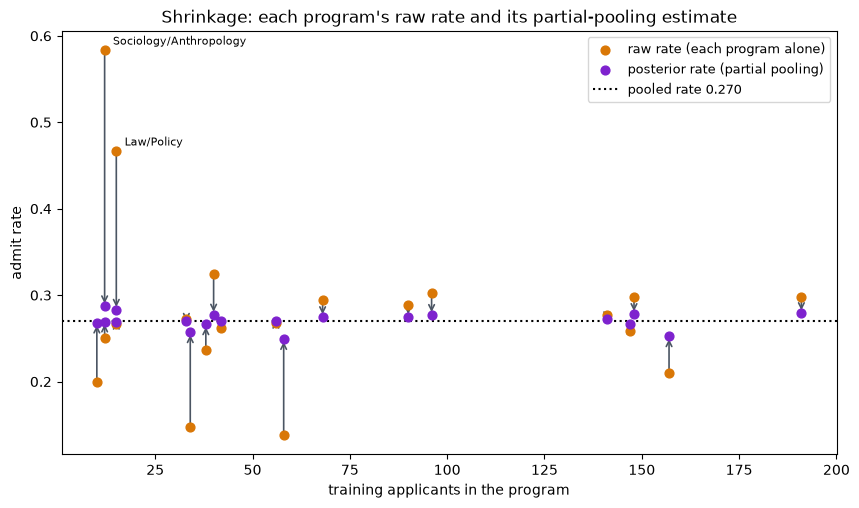

In [39]:
# Q4.3: each program's posterior admit rate (the average of its rate draws) and the shrinkage plot.
rate_draws = 1 / (1 + np.exp(-idata_programs.posterior["logit_p"]))
program_table["posterior_rate"] = rate_draws.mean(dim=("chain", "draw")).to_numpy()
movement = (program_table["posterior_rate"] - program_table["raw_rate"]).abs()
moved_most = movement.nlargest(2).index.tolist()
display(program_table.assign(moved=movement).round(3))
print(f"moved furthest: {moved_most}")
soc_post = program_table.loc["Sociology/Anthropology", "posterior_rate"]
print(f"Sociology/Anthropology: raw {soc_k / soc_n:.3f}, posterior here {soc_post:.3f}; Q3.2 posterior means "
      f"{soc_flat_mean:.3f} (flat) and {soc_prior20_mean:.3f} (weight 20); other programs {others_rate:.3f}")
print(f"a Beta prior centered on {others_rate:.3f} would need weight "
      f"{(soc_k - soc_n * soc_post) / (soc_post - others_rate):.0f} to give the same posterior mean")
shrinkage_plot(program_table, pooled_rate, label=moved_most)

In [40]:
grader.check("q4_3")

q4_3 results: All test cases passed!

**Written response: Q4.3**

- **Moved furthest:** Sociology/Anthropology, from 0.583 to 0.287, and Law/Policy, from 0.467 to 0.283, the two small programs (n = 12 and 15) furthest above the pooled 0.270, as Q4.1 predicted.
- **Large programs:** the prediction held in absolute terms, since none of the five largest moved more than 0.042, but each still moved about 70% of the way to the pooled rate; Biology & Life Sciences (n = 157) went from 0.210 to 0.252. With `sigma_alpha` near 0.12, the model expects programs to differ by less than the noise in a rate from 157 applicants (a log-odds standard error of about 1/√(157 × 0.21 × 0.79) ≈ 0.20), so Biology's own rate gets a weight of only about 0.12²/(0.12² + 0.20²) ≈ 0.3.
- **Sociology/Anthropology:** 0.287 here, against Q3.2's posterior means of 0.571 (flat prior) and 0.386 (weight 20); the hierarchical estimate is the closest to the other programs' 0.267. With the small `sigma_alpha` the data support, the model pools much harder than our hand-picked prior: a Beta prior centered on 0.267 would need a weight of about 180, not 20, to give 0.287.

## Q4.4. Add fixed slopes beside the varying intercepts

**7 points**

Programs may differ in admit rate partly because they attract different applicants. Adding applicant-level predictors with slopes shared by every program lets the program intercepts describe the differences in admission that remain after accounting for those predictors. Those remaining differences are associations, not effects of the programs.

**Task:** Build `X_slopes` from the training rows: `test_score` standardized with `score_mean` and `score_sd`, then `early_app` and `alumni` as they are. Refit Q4.2's model with `beta = pm.Normal("beta", 0, 2.5, shape=3)` added, so the log-odds are `logit_p[program_idx] + pm.math.dot(X_slopes, beta)`. Use the same sampling settings as Q4.2. Summarize `alpha0`, `sigma_alpha` and `beta`, count the divergences, and compute the posterior probability that `sigma_alpha` is below 0.1 as in Q4.2.

**Artifacts:** The summary; `sigma_alpha` with and without the slopes, printed side by side. In the written response: (1) `sigma_alpha`'s posterior mean and its probability of being below 0.1, with and without the slopes; (2) whether the change is large compared with the uncertainty in either posterior, and what it is consistent with about why the programs' raw rates differed; (3) the three slope means beside the corresponding coefficients in Q3.3, and why the two models' slopes need not agree.

**Constraints:** The same non-centered intercepts as Q4.2; `Normal(0, 2.5)` priors on the three slopes.

**Output names for the guided checks:** `idata_slopes` (`InferenceData`), `X_slopes` (array, three columns), `hier_summary_slopes` (from `az.summary(..., var_names=["alpha0", "sigma_alpha", "beta"], hdi_prob=0.95)`) `sigma_alpha_with_slopes` (float) and `p_sigma_alpha_small_slopes` (float).

In [41]:
# Q4.4: Q4.2's varying intercepts plus three slopes shared by every program.
X_slopes = np.column_stack([(train_df["test_score"] - score_mean) / score_sd,
                            train_df["early_app"], train_df["alumni"]]).astype(float)
with pm.Model() as slopes_model:
    alpha0 = pm.Normal("alpha0", 0, 2.5)
    sigma_alpha = pm.HalfNormal("sigma_alpha", 1.0)
    z = pm.Normal("z", 0, 1, shape=n_programs)
    logit_p = pm.Deterministic("logit_p", alpha0 + sigma_alpha * z)
    beta = pm.Normal("beta", 0, 2.5, shape=3)
    pm.Bernoulli("admitted", logit_p=logit_p[program_idx] + pm.math.dot(X_slopes, beta),
                 observed=y_train.to_numpy())
    idata_slopes = pm.sample(**SAMPLE, target_accept=0.9)

hier_summary_slopes = az.summary(idata_slopes, var_names=["alpha0", "sigma_alpha", "beta"], hdi_prob=0.95)
display(hier_summary_slopes)
print(f"divergences: {int(idata_slopes.sample_stats['diverging'].sum())}")
sigma_alpha_with_slopes = float(idata_slopes.posterior["sigma_alpha"].mean())
p_sigma_alpha_small_slopes = float((idata_slopes.posterior["sigma_alpha"] < 0.1).mean())

compare = {}
for label, summary, p_small in [("without slopes (Q4.2)", hier_summary, p_sigma_alpha_small),
                                ("with slopes (Q4.4)", hier_summary_slopes, p_sigma_alpha_small_slopes)]:
    row = summary.loc["sigma_alpha"]
    compare[label] = {"posterior mean": row["mean"], "posterior sd": row["sd"], "95% HDI low": row["hdi_2.5%"],
                      "95% HDI high": row["hdi_97.5%"], "P(sigma_alpha < 0.1)": p_small}
print("sigma_alpha:")
display(pd.DataFrame(compare).round(4))
display(pd.DataFrame({"Q4.4 slope (posterior mean)": hier_summary_slopes.loc[["beta[0]", "beta[1]", "beta[2]"], "mean"].to_numpy(),
                      "Q3.3 coefficient (posterior mean)": posterior_five.loc[["test_score", "early_app", "alumni"], "mean"].to_numpy()},
                     index=["test_score (per SD)", "early_app", "alumni"]).round(3))
# Q3.3 adjusts for minority and sports, which Q4.4 leaves out.
display(train_df.groupby("minority").agg(applicants=("admitted", "size"), mean_test_score=("test_score", "mean"),
                                         admit_rate=("admitted", "mean")).round(3))

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (2 chains in 2 jobs)


NUTS: [alpha0, sigma_alpha, z, beta]


Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 3 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha0,-1.198,0.082,-1.361,-1.037,0.002,0.002,2378.0,1456.0,1.0
sigma_alpha,0.093,0.076,0.000,0.232,0.002,0.003,1027.0,915.0,1.0
beta[0],0.642,0.085,0.480,0.819,0.002,0.002,3068.0,1246.0,1.0
beta[1],0.337,0.150,0.064,0.636,0.003,0.003,2940.0,1500.0,1.0
beta[2],0.699,0.268,0.141,1.224,0.004,0.007,4393.0,1395.0,1.0


divergences: 0
sigma_alpha:


,without slopes (Q4.2),with slopes (Q4.4)
posterior mean,0.1230,0.093
posterior sd,0.0910,0.076
95% HDI low,0.0000,0.000
95% HDI high,0.2990,0.232
P(sigma_alpha < 0.1),0.4755,0.631


,Q4.4 slope (posterior mean),Q3.3 coefficient (posterior mean)
test_score (per SD),0.642,0.775
early_app,0.337,0.345
alumni,0.699,0.726


,applicants,mean_test_score,admit_rate
minority,,,
0,1110,2206.529,0.247
1,293,2111.823,0.358


In [42]:
grader.check("q4_4")

q4_4 results: All test cases passed!

**Written response: Q4.4**

- **`sigma_alpha`:** posterior mean 0.123 without the slopes and 0.093 with them; the probability that it is below 0.1 rises from 0.48 to 0.63.
- **Size of the change:** the mean fell by 0.03, less than either posterior SD (0.091 and 0.076), and the 95% HDIs ([0.000, 0.299] and [0.000, 0.232]) overlap almost entirely, so the change is small. It is consistent with part of the programs' raw differences coming from who applies to them (test scores, early applications, alumni parents), but both posteriors already put the between-program spread near zero, so there was little left to explain.
- **Slopes:** test score 0.642 per SD against 0.775 in Q3.3, `early_app` 0.337 against 0.345, `alumni` 0.699 against 0.726. They need not agree because each slope is conditional on different other terms: Q3.3 adjusts for `minority` and `sports`, Q4.4 for program instead. Minority applicants score lower here (2,112 against 2,207 on average) yet are admitted more often (0.358 against 0.247), so leaving `minority` out pulls the test-score slope down, and in a logistic regression the coefficients change whenever a predictor is added or dropped.

## AC209A Extension 2. Let the test-score slope vary by program (AC209A only)

**4 points**

Q4.4 gave every program the same slope for the test score. The supplied model lets that slope vary as well: program $j$ has its own slope $\beta_j \sim N(\beta_0, \sigma_\beta^2)$, written non-centered like the intercepts, beside the varying intercepts and fixed slopes for `early_app` and `alumni`. A small $\sigma_\beta$ means that a one-standard-deviation change in test score changes the log-odds of admission by about the same amount in every program.

**Task:** Run the supplied model. Summarize `beta0`, `sigma_beta` and `sigma_alpha` (`hdi_prob=0.95`). Compute the posterior probability that `sigma_beta` is below 0.1 (the share of draws below 0.1). Build a table of each program's posterior mean slope with its `n`, and print the equal-tailed 95% interval of the slope of the program furthest from `beta0`.

**Artifacts:** The summary, the probability and the slope table. In the written response: (1) the program whose posterior mean slope is furthest from `beta0`'s posterior mean, its equal-tailed 95% interval, and whether that interval includes `beta0`'s posterior mean; (2) the 95% interval for `sigma_beta` and the probability that it is below 0.1 beside the prior's probability of the same event (0.16 under `HalfNormal(0.5)`), and how strong the evidence is that the slope differs across programs; (3) whether `sigma_alpha` changed from Q4.4.

**Constraints:** Use the supplied model unchanged. Read the probability as the strength of the evidence, not as a yes-or-no test of whether `sigma_beta` is zero. CS1090A students skip this extension.

**Output names for the guided checks:** `varying_summary` (a `DataFrame`), `p_sigma_beta_small` (float) and `program_slopes` (a `DataFrame` indexed by program).

In [43]:
# Supplied: varying intercepts and a varying test-score slope, both non-centered, with fixed slopes for
# early_app and alumni. Sampling takes longer than the earlier models.
with pm.Model() as varying_slopes_model:
    alpha0 = pm.Normal("alpha0", mu=0, sigma=2.5)
    sigma_alpha = pm.HalfNormal("sigma_alpha", sigma=1.0)
    z_alpha = pm.Normal("z_alpha", mu=0, sigma=1, shape=n_programs)
    beta0 = pm.Normal("beta0", mu=0, sigma=2.5)
    sigma_beta = pm.HalfNormal("sigma_beta", sigma=0.5)
    z_beta = pm.Normal("z_beta", mu=0, sigma=1, shape=n_programs)
    alpha = pm.Deterministic("alpha", alpha0 + sigma_alpha * z_alpha)
    beta_program = pm.Deterministic("beta_program", beta0 + sigma_beta * z_beta)
    gamma = pm.Normal("gamma", mu=0, sigma=2.5, shape=2)
    eta = alpha[program_idx] + beta_program[program_idx] * X_slopes[:, 0] + pm.math.dot(X_slopes[:, 1:], gamma)
    pm.Bernoulli("admitted", logit_p=eta, observed=y_train.to_numpy())
    idata_varying = pm.sample(draws=1000, tune=1000, chains=2, random_seed=109, target_accept=0.9, progressbar=False)
print(f"divergences {int(idata_varying.sample_stats['diverging'].sum())}")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (2 chains in 2 jobs)


NUTS: [alpha0, sigma_alpha, z_alpha, beta0, sigma_beta, z_beta, gamma]


Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 3 seconds.


We recommend running at least 4 chains for robust computation of convergence diagnostics


divergences 0


In [44]:
# AC209A Extension 2: the supplied varying-slope model, summarized.
varying_summary = az.summary(idata_varying, var_names=["beta0", "sigma_beta", "sigma_alpha"], hdi_prob=0.95)
display(varying_summary)
p_sigma_beta_small = float((idata_varying.posterior["sigma_beta"] < 0.1).mean())
print(f"P(sigma_beta < 0.1): posterior {p_sigma_beta_small:.3f}, prior HalfNormal(0.5) {stats.halfnorm.cdf(0.1 / 0.5):.3f}")

slope_draws = idata_varying.posterior["beta_program"].values.reshape(-1, n_programs)   # one row per draw
beta0_mean = float(idata_varying.posterior["beta0"].mean())
program_slopes = pd.DataFrame({"n": program_table["n"], "posterior_mean_slope": slope_draws.mean(axis=0)},
                              index=program_table.index)
program_slopes["minus_beta0_mean"] = program_slopes["posterior_mean_slope"] - beta0_mean
display(program_slopes.round(3))

furthest = program_slopes["minus_beta0_mean"].abs().idxmax()
low, high = np.percentile(slope_draws[:, program_table.index.get_loc(furthest)], [2.5, 97.5])
print(f"furthest from beta0's posterior mean ({beta0_mean:.3f}): {furthest} (n = {program_slopes.loc[furthest, 'n']}), "
      f"mean slope {program_slopes.loc[furthest, 'posterior_mean_slope']:.3f}, 95% interval [{low:.3f}, {high:.3f}]; "
      f"includes beta0's mean: {low <= beta0_mean <= high}")
print(f"sigma_alpha posterior mean: {float(idata_varying.posterior['sigma_alpha'].mean()):.3f} here, "
      f"{sigma_alpha_with_slopes:.3f} in Q4.4")

,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
beta0,0.656,0.100,0.454,0.849,0.003,0.002,1308.0,965.0,1.00
sigma_beta,0.161,0.115,0.001,0.380,0.004,0.003,635.0,828.0,1.01
sigma_alpha,0.094,0.077,0.000,0.239,0.002,0.002,998.0,1086.0,1.00


P(sigma_beta < 0.1): posterior 0.361, prior HalfNormal(0.5) 0.159


,n,posterior_mean_slope,minus_beta0_mean
program,,,
Humanities (General),10,0.685,0.029
Philosophy,12,0.650,-0.007
Sociology/Anthropology,12,0.608,-0.048
Environmental & Earth,15,0.733,0.077
Law/Policy,15,0.663,0.007
History,33,0.553,-0.103
Arts/Media/Architecture,34,0.714,0.058
Undecided/Undeclared,38,0.691,0.035
Chemistry,40,0.738,0.082


furthest from beta0's posterior mean (0.656): Political Science & IR (n = 141), mean slope 0.535, 95% interval [0.120, 0.838]; includes beta0's mean: True
sigma_alpha posterior mean: 0.094 here, 0.093 in Q4.4


In [45]:
grader.check("q4_ac209")

q4_ac209 results: All test cases passed!

**Written response: AC209A Extension 2**

- **Furthest slope:** Political Science & IR (n = 141), posterior mean 0.535 against `beta0`'s 0.656; its 95% interval [0.120, 0.838] includes 0.656.
- **`sigma_beta`:** 95% HDI [0.001, 0.380] (mean 0.161), and P(`sigma_beta` < 0.1) = 0.361 against 0.159 under the HalfNormal(0.5) prior. The data more than doubled the probability of a near-zero spread, yet 64% of the posterior is still above 0.1, so the evidence that the test-score slope differs across programs is weak either way: all twenty program slopes lie between 0.535 and 0.738.
- **`sigma_alpha`:** 0.094 here against 0.093 in Q4.4, essentially unchanged.

## Wrap-up

Name one limitation of the admissions file that no question above asked about, and one analysis in this assignment whose conclusion it could change.

<div class="alert alert-info" style="color: #4a4a4a; background-color: #fbe8ff; border-color: #eed4db; border-width: 1px; border-radius: 3px; padding: 10px;">

* How many hours did you spend on this assignment? Store an int or float in `hours_spent_on_hw`. If you worked in a group, report the average per person.
* Briefly describe how you used AI assistance and how you checked its contributions.
* (Optional) Which aspect of the assignment did you find most challenging?

</div>

In [46]:
# Report your hours here. Replace None with an int or float.
hours_spent_on_hw = None

In [47]:
print("Notebook runtime, seconds:", round(time.time() - notebook_start, 1))

Notebook runtime, seconds: 21.5


In [48]:
# Wrap-up: the file has no application-year column, but the free-text field mentions years.
mentioned = df["add_info"].dropna().str.findall(r"\b(20[0-2]\d)\b").explode().dropna().astype(int)
print(f"{mentioned.size:,} year mentions in add_info from {mentioned.min()} to {mentioned.max()}; "
      f"middle 90% from {mentioned.quantile(0.05):.0f} to {mentioned.quantile(0.95):.0f}")

2,732 year mentions in add_info from 2000 to 2018; middle 90% from 2004 to 2014


**Written response: Wrap-up**

- **Limitation and the analysis it affects:** the file has no application-year column, yet its free text mentions years from 2000 to 2018 (the middle 90% from 2004 to 2014), so it pools about a decade of admission cycles, over which both colleges' admit rates fell. It could change Q2.2's threshold: we chose 0.3 to flag 37.1% of applicants and the test rows agreed (37.2%), but both sets mix the same years, so in a single newer cycle with a different admit rate or applicant pool the same threshold could flag a share outside the counselor's 30% to 40%.
- **AI use:** we used Claude Code (Claude Opus 5.5) to write the code and draft these answers. Its work was checked by rerunning the notebook from a fresh kernel with every guided check passing, by comparing the hand computations with scikit-learn's (Q1.1's counts, and Q3.1's BFGS fit against Q1.2), and by matching every number in these answers to the printed output.